In [2]:
# --- SETUP CELL (run this first every session) ---
from google.colab import drive
drive.mount("/content/drive")

%cd /content/drive/MyDrive/home_credit_lab

import os
import time
import tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def log_run(part, split, features, settings, runtime, metrics, notes):
    row = pd.DataFrame([{
        "data_version": "v1",
        "part": part,
        "split": split,
        "features": features,
        "settings": settings,
        "runtime_sec": runtime,
        "metrics": metrics,
        "notes": notes
    }])
    row.to_csv("experiment_log.csv", mode="a",
               header=not os.path.exists("experiment_log.csv"), index=False)

print("Setup ready! Files in folder:", os.listdir("."))

Mounted at /content/drive
/content/drive/MyDrive/home_credit_lab
Setup ready! Files in folder: []


# Part 1: Audit, Split, Leakage

In [3]:
import os
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Shared logger (used across parts)
def log_run(part, split, features, settings, runtime, metrics, notes):
    row = pd.DataFrame([{
        "data_version": "v1",
        "part": part,
        "split": split,
        "features": features,
        "settings": settings,
        "runtime_sec": runtime,
        "metrics": metrics,
        "notes": notes
    }])
    row.to_csv("experiment_log.csv", mode="a",
               header=not os.path.exists("experiment_log.csv"), index=False)

# 1. Load dataset and run basic audit
df = pd.read_csv("application_train.csv")
print("Shape:", df.shape)
print("Default rate (TARGET=1):", round(df["TARGET"].mean(), 4))
print("Duplicate rows:", df.duplicated().sum())

# Top 15 columns by missing percentage
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
print("\nTop 15 columns by missing %:")
print(missing_pct.head(15).round(2))

# Fix DAYS_EMPLOYED == 365243 anomaly
anomaly_count = (df["DAYS_EMPLOYED"] == 365243).sum()
print("\nRows with DAYS_EMPLOYED == 365243:", anomaly_count)
df["emp_anomaly"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

# 2. Note on SK_ID_CURR
print("\nKey note: SK_ID_CURR is the unique loan application ID.")
print("Other Home Credit tables linking to SK_ID_CURR: bureau, previous_application, installments_payments.")

Shape: (307511, 122)
Default rate (TARGET=1): 0.0807
Duplicate rows: 0

Top 15 columns by missing %:
COMMONAREA_AVG              69.87
COMMONAREA_MODE             69.87
COMMONAREA_MEDI             69.87
NONLIVINGAPARTMENTS_MEDI    69.43
NONLIVINGAPARTMENTS_MODE    69.43
NONLIVINGAPARTMENTS_AVG     69.43
FONDKAPREMONT_MODE          68.39
LIVINGAPARTMENTS_AVG        68.35
LIVINGAPARTMENTS_MEDI       68.35
LIVINGAPARTMENTS_MODE       68.35
FLOORSMIN_MODE              67.85
FLOORSMIN_AVG               67.85
FLOORSMIN_MEDI              67.85
YEARS_BUILD_AVG             66.50
YEARS_BUILD_MODE            66.50
dtype: float64

Rows with DAYS_EMPLOYED == 365243: 55374

Key note: SK_ID_CURR is the unique loan application ID.
Other Home Credit tables linking to SK_ID_CURR: bureau, previous_application, installments_payments.


In [4]:
# 3. Stratified 85% dev / 15% final_test split
dev, final_test = train_test_split(
    df,
    test_size=0.15,
    stratify=df["TARGET"],
    random_state=24
)

dev.to_csv("dev.csv", index=False)
final_test.to_csv("final_test.csv", index=False)

print("dev shape:", dev.shape, "| default rate:", round(dev["TARGET"].mean(), 4))
print("final_test shape:", final_test.shape, "| default rate:", round(final_test["TARGET"].mean(), 4))

dev shape: (261384, 123) | default rate: 0.0807
final_test shape: (46127, 123) | default rate: 0.0807


In [5]:
# 4. LEAKAGE DEMO 1: imputer + scaler on ALL dev vs. train only
num_cols = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
    "CNT_CHILDREN", "CNT_FAM_MEMBERS", "REGION_RATING_CLIENT",
    "REGION_POPULATION_RELATIVE", "OWN_CAR_AGE", "EXT_SOURCE_1",
    "EXT_SOURCE_2", "EXT_SOURCE_3", "emp_anomaly"
]

X_dev = dev[num_cols].copy()
y_dev = dev["TARGET"].copy()

# --- (a) LEAKY: fit imputer + scaler on ALL dev data before splitting ---
t0 = time.time()
imp_leaky = SimpleImputer(strategy="median")
scl_leaky = StandardScaler()
X_all_prep = scl_leaky.fit_transform(imp_leaky.fit_transform(X_dev))

X_tr_l, X_val_l, y_tr_l, y_val_l = train_test_split(
    X_all_prep, y_dev, test_size=0.20, stratify=y_dev, random_state=24
)
clf_l = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
clf_l.fit(X_tr_l, y_tr_l)
auc_leaky = roc_auc_score(y_val_l, clf_l.predict_proba(X_val_l)[:, 1])
rt_leaky = round(time.time() - t0, 3)

# --- (b) CLEAN: split first, then fit imputer + scaler on train only ---
t0 = time.time()
X_tr, X_val, y_tr, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=24
)
imp_clean = SimpleImputer(strategy="median")
scl_clean = StandardScaler()
X_tr_c = scl_clean.fit_transform(imp_clean.fit_transform(X_tr))
X_val_c = scl_clean.transform(imp_clean.transform(X_val))

clf_c = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
clf_c.fit(X_tr_c, y_tr)
auc_clean = roc_auc_score(y_val, clf_c.predict_proba(X_val_c)[:, 1])
rt_clean = round(time.time() - t0, 3)

print(f"Leakage Demo 1 - Leaky ROC-AUC: {auc_leaky:.5f}")
print(f"Leakage Demo 1 - Clean ROC-AUC: {auc_clean:.5f}")

log_run("Part 1", "dev 80/20", "base_numeric+emp_anomaly", "LogReg balanced, leaky prep",
        rt_leaky, f"roc_auc={auc_leaky:.5f}", "Leakage demo 1: imputer+scaler fit on full dev")
log_run("Part 1", "dev 80/20", "base_numeric+emp_anomaly", "LogReg balanced, clean prep",
        rt_clean, f"roc_auc={auc_clean:.5f}", "Leakage demo 1: imputer+scaler fit on train only")

Leakage Demo 1 - Leaky ROC-AUC: 0.74009
Leakage Demo 1 - Clean ROC-AUC: 0.74012


In [6]:
# 5. LEAKAGE DEMO 2: target-encode OCCUPATION_TYPE
occ_dev = dev["OCCUPATION_TYPE"].fillna("Missing")
idx_tr, idx_val = train_test_split(
    dev.index, test_size=0.20, stratify=y_dev, random_state=24
)

# Prepare base numeric features cleanly (train-only fit)
imp = SimpleImputer(strategy="median")
scl = StandardScaler()
X_tr_num = scl.fit_transform(imp.fit_transform(X_dev.loc[idx_tr]))
X_val_num = scl.transform(imp.transform(X_dev.loc[idx_val]))
y_tr2 = y_dev.loc[idx_tr]
y_val2 = y_dev.loc[idx_val]

# --- (a) LEAKY: target encoding computed on full dev ---
t0 = time.time()
occ_means_full = y_dev.groupby(occ_dev).mean()
occ_tr_leaky = occ_dev.loc[idx_tr].map(occ_means_full).values.reshape(-1, 1)
occ_val_leaky = occ_dev.loc[idx_val].map(occ_means_full).values.reshape(-1, 1)

X_tr_te_l = np.hstack([X_tr_num, occ_tr_leaky])
X_val_te_l = np.hstack([X_val_num, occ_val_leaky])

clf_te_l = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
clf_te_l.fit(X_tr_te_l, y_tr2)
auc_te_leaky = roc_auc_score(y_val2, clf_te_l.predict_proba(X_val_te_l)[:, 1])
rt_te_l = round(time.time() - t0, 3)

# --- (b) CLEAN: target encoding computed on train only ---
t0 = time.time()
occ_means_train = y_tr2.groupby(occ_dev.loc[idx_tr]).mean()
global_mean = y_tr2.mean()
occ_tr_clean = occ_dev.loc[idx_tr].map(occ_means_train).fillna(global_mean).values.reshape(-1, 1)
occ_val_clean = occ_dev.loc[idx_val].map(occ_means_train).fillna(global_mean).values.reshape(-1, 1)

X_tr_te_c = np.hstack([X_tr_num, occ_tr_clean])
X_val_te_c = np.hstack([X_val_num, occ_val_clean])

clf_te_c = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
clf_te_c.fit(X_tr_te_c, y_tr2)
auc_te_clean = roc_auc_score(y_val2, clf_te_c.predict_proba(X_val_te_c)[:, 1])
rt_te_c = round(time.time() - t0, 3)

print(f"Leakage Demo 2 - Leaky Target Encoding ROC-AUC: {auc_te_leaky:.5f}")
print(f"Leakage Demo 2 - Clean Target Encoding ROC-AUC: {auc_te_clean:.5f}")

log_run("Part 1", "dev 80/20", "base_numeric+OCCUPATION_TYPE_te", "LogReg balanced, leaky TE",
        rt_te_l, f"roc_auc={auc_te_leaky:.5f}", "Leakage demo 2: target encoding on full dev")
log_run("Part 1", "dev 80/20", "base_numeric+OCCUPATION_TYPE_te", "LogReg balanced, clean TE",
        rt_te_c, f"roc_auc={auc_te_clean:.5f}", "Leakage demo 2: target encoding on train only")

Leakage Demo 2 - Leaky Target Encoding ROC-AUC: 0.74296
Leakage Demo 2 - Clean Target Encoding ROC-AUC: 0.74291


In [7]:
# 6. Why each demo is unrealistic + 3 post-decision leakage examples
print("Why the demos are unrealistic:")
print("1. Demo 1 uses validation rows to compute medians, means, and stds that would not exist at prediction time.")
print("2. Even small preprocessing leaks give the model a subtle preview of the validation distribution.")
print("3. Demo 2 uses validation TARGET labels directly inside OCCUPATION_TYPE averages, leaking the answer.")
print("4. In production, new loan applicants have no known TARGET label, so target encoding must use training data only.")

print("\n3 examples of features NOT known at loan decision time:")
print("1. Future installment payment delays or missed payments (from installments_payments after approval).")
print("2. Loan write-off, recovery, or collection status recorded months after disbursement.")
print("3. Post-approval credit card balance or credit limit changes on the newly issued loan.")

Why the demos are unrealistic:
1. Demo 1 uses validation rows to compute medians, means, and stds that would not exist at prediction time.
2. Even small preprocessing leaks give the model a subtle preview of the validation distribution.
3. Demo 2 uses validation TARGET labels directly inside OCCUPATION_TYPE averages, leaking the answer.
4. In production, new loan applicants have no known TARGET label, so target encoding must use training data only.

3 examples of features NOT known at loan decision time:
1. Future installment payment delays or missed payments (from installments_payments after approval).
2. Loan write-off, recovery, or collection status recorded months after disbursement.
3. Post-approval credit card balance or credit limit changes on the newly issued loan.


# Part 2: Missing Values & New Features


Loaded dev.csv shape: (261384, 123)


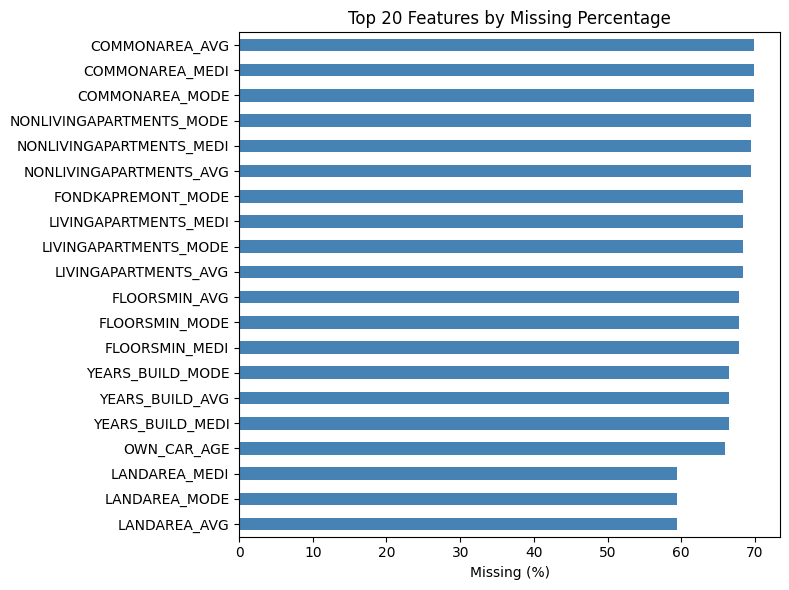

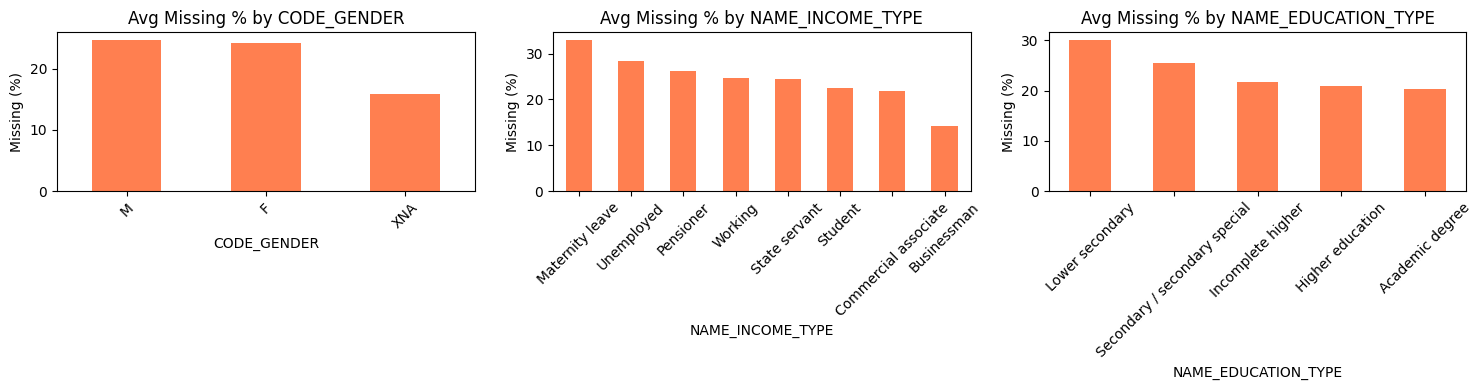

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Load dev.csv saved in Part 1
dev = pd.read_csv("dev.csv")
print("Loaded dev.csv shape:", dev.shape)

# 1a. Plot top 20 features by missing %
miss_pct = (dev.isnull().mean() * 100).sort_values(ascending=False)
top20_miss = miss_pct.head(20)

plt.figure(figsize=(8, 6))
top20_miss.iloc[::-1].plot(kind="barh", color="steelblue")
plt.xlabel("Missing (%)")
plt.title("Top 20 Features by Missing Percentage")
plt.tight_layout()
plt.show()

# 1b. Plot average row missing % by CODE_GENDER, NAME_INCOME_TYPE, NAME_EDUCATION_TYPE
dev_row_miss = dev.isnull().mean(axis=1) * 100
group_cols = ["CODE_GENDER", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, group_cols):
    grp_miss = dev_row_miss.groupby(dev[col]).mean().sort_values(ascending=False)
    grp_miss.plot(kind="bar", ax=ax, color="coral")
    ax.set_title(f"Avg Missing % by {col}")
    ax.set_ylabel("Missing (%)")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# 2. Create NEW FEATURES with plain pandas (count missing_count before adding new columns)
dev["missing_count"] = dev.isnull().sum(axis=1)

dev["age_years"] = -dev["DAYS_BIRTH"] / 365.0
dev["employed_years"] = -dev["DAYS_EMPLOYED"] / 365.0  # already NaN where anomaly=1
dev["employed_to_age"] = dev["employed_years"] / dev["age_years"]
dev["credit_to_income"] = dev["AMT_CREDIT"] / dev["AMT_INCOME_TOTAL"]
dev["annuity_to_income"] = dev["AMT_ANNUITY"] / dev["AMT_INCOME_TOTAL"]
dev["loan_term"] = dev["AMT_CREDIT"] / dev["AMT_ANNUITY"]
dev["income_per_person"] = dev["AMT_INCOME_TOTAL"] / dev["CNT_FAM_MEMBERS"]
dev["price_gap"] = (dev["AMT_CREDIT"] - dev["AMT_GOODS_PRICE"]) / dev["AMT_GOODS_PRICE"]
dev["ext_mean"] = dev[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
dev["income_group"] = pd.qcut(
    dev["AMT_INCOME_TOTAL"], q=4, labels=["Poor", "Lower-mid", "Upper-mid", "Rich"]
)

dev.to_csv("dev_fe.csv", index=False)
print("Saved dev_fe.csv with shape:", dev.shape)
print(dev[["age_years", "employed_years", "credit_to_income", "loan_term", "ext_mean", "missing_count", "income_group"]].head(3))

Saved dev_fe.csv with shape: (261384, 134)
   age_years  employed_years  credit_to_income  loan_term  ext_mean  \
0  37.186301       14.391781          1.600000  20.000000  0.652408   
1  35.526027       14.263014          2.691556  27.659283  0.581994   
2  31.153425        8.312329          2.461600  18.717612  0.689146   

   missing_count income_group  
0             48         Poor  
1             48    Upper-mid  
2             27         Rich  


In [10]:
# 3. Compare 3 missing-value methods (A, B, C) using LogisticRegression on 80/20 split
# Use original numeric columns from dev (excluding ID and TARGET)
orig_num_cols = [c for c in dev.select_dtypes(include=[np.number]).columns
                 if c not in ["SK_ID_CURR", "TARGET", "missing_count", "age_years",
                              "employed_years", "employed_to_age", "credit_to_income",
                              "annuity_to_income", "loan_term", "income_per_person",
                              "price_gap", "ext_mean"]]

X_raw = dev[orig_num_cols].copy()
y = dev["TARGET"].copy()

X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=24
)

def run_missing_method(X_tr_df, X_val_df, method_name):
    t0 = time.time()
    X_tr_m = X_tr_df.copy()
    X_val_m = X_val_df.copy()

    if method_name == "B":
        # Top 5 most-missing columns (computed on train only)
        top5 = X_tr_m.isnull().mean().sort_values(ascending=False).head(5).index.tolist()
        for col in top5:
            X_tr_m[col + "_was_missing"] = X_tr_m[col].isnull().astype(int)
            X_val_m[col + "_was_missing"] = X_val_m[col].isnull().astype(int)

    elif method_name == "C":
        # Drop columns with >50% missing (computed on train only)
        keep_cols = X_tr_m.columns[X_tr_m.isnull().mean() <= 0.50]
        X_tr_m = X_tr_m[keep_cols]
        X_val_m = X_val_m[keep_cols]

    # Fit imputer and scaler on train only
    imp = SimpleImputer(strategy="median")
    scl = StandardScaler()
    X_tr_prep = scl.fit_transform(imp.fit_transform(X_tr_m))
    X_val_prep = scl.transform(imp.transform(X_val_m))

    clf = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
    clf.fit(X_tr_prep, y_tr)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val_prep)[:, 1])
    rt = round(time.time() - t0, 3)
    return auc, rt

results_abc = []
labels = {"A": "Median fill", "B": "Median + top-5 was_missing flags", "C": "Drop >50% missing + median"}
for m in ["A", "B", "C"]:
    auc, rt = run_missing_method(X_tr_raw, X_val_raw, m)
    results_abc.append({"Method": m, "Description": labels[m], "ROC_AUC": round(auc, 5), "Runtime_sec": rt})
    log_run("Part 2", "dev 80/20", f"orig_numeric (method {m})", "LogReg balanced",
            rt, f"roc_auc={auc:.5f}", labels[m])

res_df = pd.DataFrame(results_abc)
print(res_df.to_string(index=False))

Method                      Description  ROC_AUC  Runtime_sec
     A                      Median fill  0.74601       33.498
     B Median + top-5 was_missing flags  0.74590       25.633
     C       Drop >50% missing + median  0.73912        5.578


ROC-AUC vs. Extra Hidden %:
method            A        B        C
hidden_pct                           
0           0.74601  0.74590  0.73912
10          0.73121  0.73107  0.72514
25          0.71756  0.71767  0.70987
40          0.69669  0.69660  0.65492


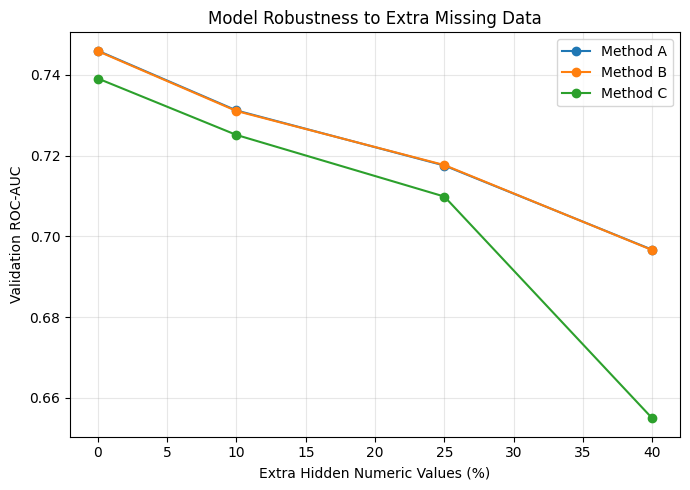


Best method at 0% extra hidden: Method A (AUC=0.74601)
Loses >0.02 AUC at 25% extra hidden values (drop=0.02845).
Unreliable beyond ~25% extra missingness because key signals like EXT_SOURCE get erased.


In [11]:
# 4. Stress test: hide an EXTRA 10%, 25%, 40% of numeric values and repeat A, B, C
rng = np.random.RandomState(24)
hide_levels = [0.0, 0.10, 0.25, 0.40]
stress_rows = []

for p in hide_levels:
    if p == 0.0:
        X_tr_h = X_tr_raw.copy()
        X_val_h = X_val_raw.copy()
    else:
        X_tr_h = X_tr_raw.mask(rng.rand(*X_tr_raw.shape) < p)
        X_val_h = X_val_raw.mask(rng.rand(*X_val_raw.shape) < p)

    for m in ["A", "B", "C"]:
        auc, rt = run_missing_method(X_tr_h, X_val_h, m)
        stress_rows.append({"hidden_pct": int(p * 100), "method": m, "roc_auc": auc})
        if p > 0:
            log_run("Part 2", "dev 80/20", f"orig_numeric+hide{int(p*100)}% ({m})",
                    "LogReg balanced", rt, f"roc_auc={auc:.5f}", f"Extra {int(p*100)}% hidden")

stress_df = pd.DataFrame(stress_rows)
pivot_stress = stress_df.pivot(index="hidden_pct", columns="method", values="roc_auc")
print("ROC-AUC vs. Extra Hidden %:")
print(pivot_stress.round(5))

# Plot 3 lines
plt.figure(figsize=(7, 5))
for m in ["A", "B", "C"]:
    plt.plot(pivot_stress.index, pivot_stress[m], marker="o", label=f"Method {m}")
plt.xlabel("Extra Hidden Numeric Values (%)")
plt.ylabel("Validation ROC-AUC")
plt.title("Model Robustness to Extra Missing Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Find best baseline method and where it loses > 0.02 AUC
best_m = pivot_stress.loc[0].idxmax()
base_auc = pivot_stress.loc[0, best_m]
drop_df = base_auc - pivot_stress[best_m]
lost_02 = drop_df[drop_df > 0.02]

print(f"\nBest method at 0% extra hidden: Method {best_m} (AUC={base_auc:.5f})")
if len(lost_02) > 0:
    first_bad = lost_02.index[0]
    print(f"Loses >0.02 AUC at {first_bad}% extra hidden values (drop={lost_02.iloc[0]:.5f}).")
    print(f"Unreliable beyond ~{first_bad}% extra missingness because key signals like EXT_SOURCE get erased.")
else:
    print("Did not lose >0.02 AUC even at 40% extra hidden values.")

In [12]:
# 5. Before vs. After New Features: base features vs. base + new
base_num = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
    "CNT_CHILDREN", "CNT_FAM_MEMBERS", "REGION_RATING_CLIENT",
    "REGION_POPULATION_RELATIVE", "OWN_CAR_AGE", "EXT_SOURCE_1",
    "EXT_SOURCE_2", "EXT_SOURCE_3"
]
base_cat = [
    "CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY",
    "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS"
]
new_num = [
    "age_years", "employed_years", "employed_to_age", "credit_to_income",
    "annuity_to_income", "loan_term", "income_per_person", "price_gap",
    "ext_mean", "missing_count", "emp_anomaly"
]

def eval_feature_set(df_in, num_list, cat_list, tag):
    t0 = time.time()
    X_cat = pd.get_dummies(df_in[cat_list], drop_first=True)
    X_all = pd.concat([df_in[num_list], X_cat], axis=1)
    y_all = df_in["TARGET"]

    X_tr, X_val, y_tr, y_val = train_test_split(
        X_all, y_all, test_size=0.20, stratify=y_all, random_state=24
    )
    imp = SimpleImputer(strategy="median")
    scl = StandardScaler()
    X_tr_p = scl.fit_transform(imp.fit_transform(X_tr))
    X_val_p = scl.transform(imp.transform(X_val))

    clf = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
    clf.fit(X_tr_p, y_tr)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val_p)[:, 1])
    rt = round(time.time() - t0, 3)
    log_run("Part 2", "dev 80/20", tag, "LogReg balanced", rt, f"roc_auc={auc:.5f}", "Before/after feature comparison")
    return auc

auc_base = eval_feature_set(dev, base_num, base_cat, "base_num+base_cat")
auc_plus = eval_feature_set(dev, base_num + new_num, base_cat + ["income_group"], "base+new_features")

print(f"Base features ROC-AUC:       {auc_base:.5f}")
print(f"Base + New features ROC-AUC: {auc_plus:.5f}")
print(f"ROC-AUC Difference:          {auc_plus - auc_base:+.5f}")

Base features ROC-AUC:       0.75026
Base + New features ROC-AUC: 0.75259
ROC-AUC Difference:          +0.00233


# Part 3: Segment Stories & K-Means


Loaded dev_fe.csv shape: (261384, 134)

1. Default rate by income_group:
               size  default_pct
income_group                    
Lower-mid     46529         8.62
Poor          85272         8.37
Rich          60851         6.92
Upper-mid     68732         8.35


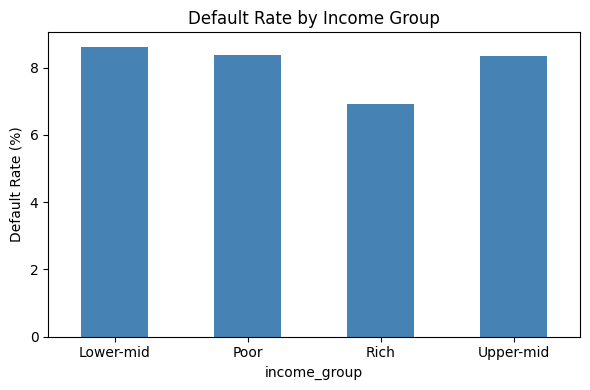

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Load dev_fe.csv saved in Part 2
dev_fe = pd.read_csv("dev_fe.csv")
print("Loaded dev_fe.csv shape:", dev_fe.shape)

# Helper to summarize groups and ignore groups smaller than 200
def segment_summary(df_in, group_cols):
    grp = df_in.groupby(group_cols, observed=True)["TARGET"].agg(size="count", default_rate="mean")
    grp = grp[grp["size"] >= 200].copy()
    grp["default_pct"] = (grp["default_rate"] * 100).round(2)
    return grp[["size", "default_pct"]]

# 1. Default rate by income_group
inc_tbl = segment_summary(dev_fe, "income_group")
print("\n1. Default rate by income_group:")
print(inc_tbl)

inc_tbl["default_pct"].plot(kind="bar", color="steelblue", figsize=(6, 4))
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Income Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


2. Default rate by income_group x NAME_EDUCATION_TYPE (size >= 200):
                                             size  default_pct
income_group NAME_EDUCATION_TYPE                              
Lower-mid    Higher education                9581         5.49
             Incomplete higher               1580         7.47
             Lower secondary                  565        13.27
             Secondary / secondary special  34790         9.46
Poor         Higher education               12342         5.79
             Incomplete higher               2196         9.52
             Lower secondary                 1685        10.33
             Secondary / secondary special  69028         8.75
Rich         Higher education               24227         4.68
             Incomplete higher               2447         8.13
             Lower secondary                  324         9.57
             Secondary / secondary special  33782         8.42
Upper-mid    Higher education               1771

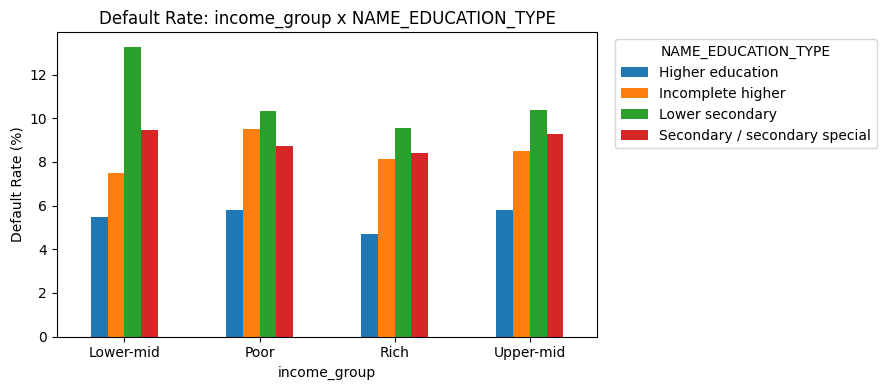


2. Default rate by income_group x FLAG_OWN_CAR (size >= 200):
                            size  default_pct
income_group FLAG_OWN_CAR                    
Lower-mid    N             32166         8.78
             Y             14363         8.26
Poor         N             66400         8.62
             Y             18872         7.50
Rich         N             31094         7.69
             Y             29757         6.11
Upper-mid    N             42802         8.72
             Y             25930         7.76


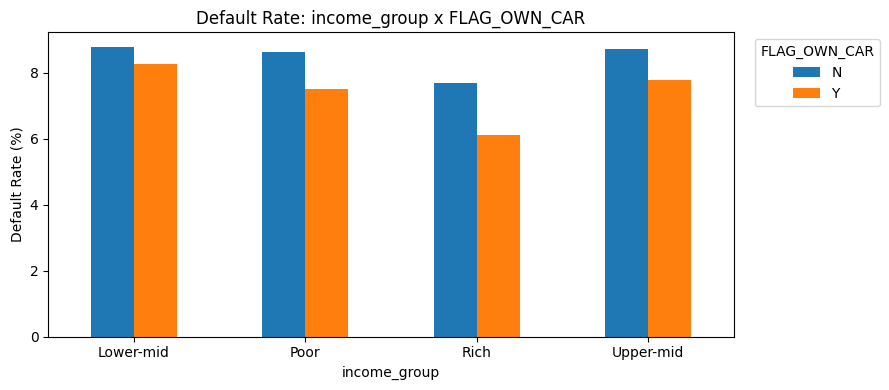


2. Default rate by income_group x FLAG_OWN_REALTY (size >= 200):
                               size  default_pct
income_group FLAG_OWN_REALTY                    
Lower-mid    N                14504         8.96
             Y                32025         8.46
Poor         N                26410         9.00
             Y                58862         8.09
Rich         N                18524         6.62
             Y                42327         7.05
Upper-mid    N                20634         8.54
             Y                48098         8.27


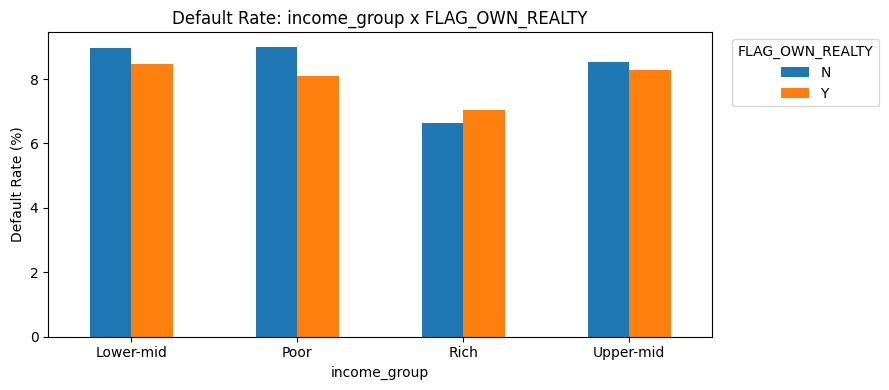

In [15]:
# 2. income_group x NAME_EDUCATION_TYPE, x FLAG_OWN_CAR, x FLAG_OWN_REALTY
cross_cols = ["NAME_EDUCATION_TYPE", "FLAG_OWN_CAR", "FLAG_OWN_REALTY"]

for col in cross_cols:
    tbl = segment_summary(dev_fe, ["income_group", col])
    print(f"\n2. Default rate by income_group x {col} (size >= 200):")
    print(tbl)

    plot_df = tbl["default_pct"].unstack(col)
    plot_df.plot(kind="bar", figsize=(9, 4))
    plt.ylabel("Default Rate (%)")
    plt.title(f"Default Rate: income_group x {col}")
    plt.xticks(rotation=0)
    plt.legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

3. Poor applicants by credit_to_income median:
                                       size  default_pct
poor_credit_split                                       
Poor + Above-Median Credit/Income     42636         9.01
Poor + At/Below-Median Credit/Income  42636         7.73

4. Young + Low Income vs. Older + High Income:
                            size  default_pct
age_inc_seg                                  
Older (>45) + High Income  25419          5.9
Young (<30) + Low Income   13066         12.6

5. Employed vs. Not Employed:
                      size  default_pct
emp_status                             
Employed            214391         8.64
Not Employed (NaN)   46993         5.47


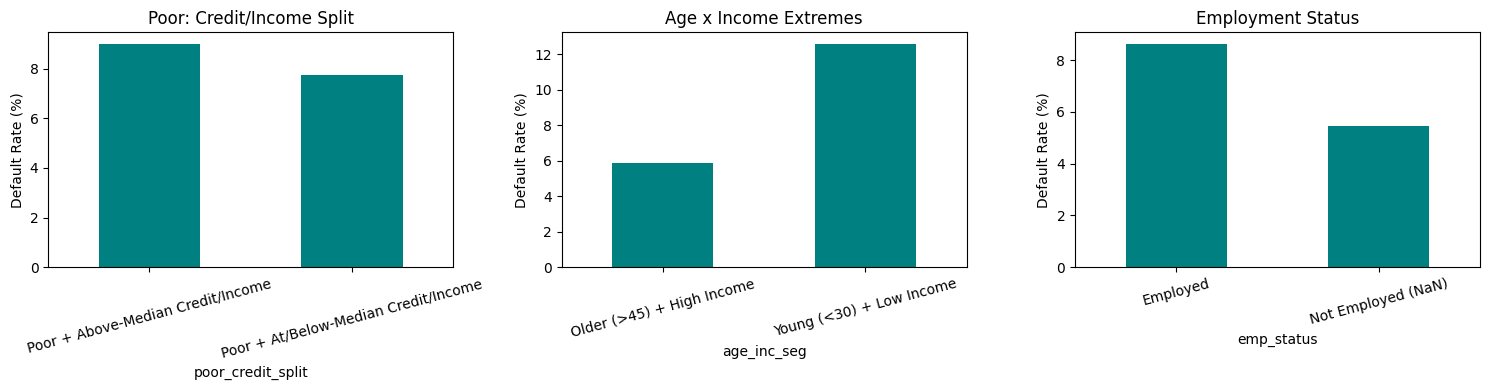

In [14]:
# 3. Poor applicants: credit_to_income above median vs. other poor applicants
poor_df = dev_fe[dev_fe["income_group"] == "Poor"].copy()
poor_med_c2i = poor_df["credit_to_income"].median()
poor_df["poor_credit_split"] = np.where(
    poor_df["credit_to_income"] > poor_med_c2i,
    "Poor + Above-Median Credit/Income",
    "Poor + At/Below-Median Credit/Income"
)
poor_tbl = segment_summary(poor_df, "poor_credit_split")
print("3. Poor applicants by credit_to_income median:")
print(poor_tbl)

# 4. Young (<30) with low income vs. older (>45) with high income
young_low = (dev_fe["age_years"] < 30) & (dev_fe["income_group"] == "Poor")
older_high = (dev_fe["age_years"] > 45) & (dev_fe["income_group"] == "Rich")
age_inc_df = dev_fe[young_low | older_high].copy()
age_inc_df["age_inc_seg"] = np.where(
    age_inc_df["age_years"] < 30,
    "Young (<30) + Low Income",
    "Older (>45) + High Income"
)
age_inc_tbl = segment_summary(age_inc_df, "age_inc_seg")
print("\n4. Young + Low Income vs. Older + High Income:")
print(age_inc_tbl)

# 5. Employed vs. not employed (employed_years NaN)
emp_df = dev_fe.copy()
emp_df["emp_status"] = np.where(emp_df["employed_years"].isna(), "Not Employed (NaN)", "Employed")
emp_tbl = segment_summary(emp_df, "emp_status")
print("\n5. Employed vs. Not Employed:")
print(emp_tbl)

# Bar plots for 3, 4, 5
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, tbl, title in zip(
    axes,
    [poor_tbl, age_inc_tbl, emp_tbl],
    ["Poor: Credit/Income Split", "Age x Income Extremes", "Employment Status"]
):
    tbl["default_pct"].plot(kind="bar", ax=ax, color="teal")
    ax.set_title(title)
    ax.set_ylabel("Default Rate (%)")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

6a. Group sizes (income_group x loan_term quartile):
loan_term_q   Q1 (Short)     Q2     Q3  Q4 (Long)
income_group                                     
Lower-mid          11746  12070  11431      11281
Poor               23798  24228  19938      17306
Rich               13510  14815  14096      18428
Upper-mid          16303  16886  17230      18308

6b. Default % (income_group x loan_term quartile, size >= 200):
loan_term_q   Q1 (Short)    Q2     Q3  Q4 (Long)
income_group                                    
Lower-mid           9.84  8.59   9.27       6.70
Poor                8.33  8.11  10.09       6.81
Rich                8.18  6.29   7.48       6.07
Upper-mid           9.68  8.13   8.85       6.93


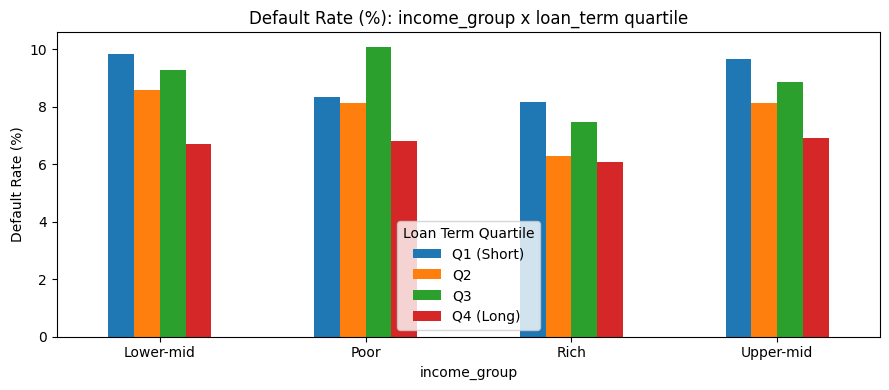


7. Three plain-English findings:
1. Young (<30) low-income applicants default at 12.6% vs. 5.9% for older (>45) high-income applicants.
2. Employed applicants default at 8.64% vs. 5.47% for applicants with missing/anomalous employment.
3. Within the Poor group, above-median credit-to-income borrowers default at 9.01% vs. 7.73% for lower ratios.


In [16]:
# 6. Pivot: income_group x loan_term quartile = default %
dev_fe["loan_term_q"] = pd.qcut(
    dev_fe["loan_term"], q=4, labels=["Q1 (Short)", "Q2", "Q3", "Q4 (Long)"]
)

piv_cnt = pd.pivot_table(
    dev_fe, values="TARGET", index="income_group", columns="loan_term_q",
    aggfunc="count", observed=True
)
piv_pct = pd.pivot_table(
    dev_fe, values="TARGET", index="income_group", columns="loan_term_q",
    aggfunc="mean", observed=True
) * 100

# Ignore cells smaller than 200
piv_pct = piv_pct.where(piv_cnt >= 200)

print("6a. Group sizes (income_group x loan_term quartile):")
print(piv_cnt)
print("\n6b. Default % (income_group x loan_term quartile, size >= 200):")
print(piv_pct.round(2))

piv_pct.plot(kind="bar", figsize=(9, 4))
plt.ylabel("Default Rate (%)")
plt.title("Default Rate (%): income_group x loan_term quartile")
plt.xticks(rotation=0)
plt.legend(title="Loan Term Quartile")
plt.tight_layout()
plt.show()

# 7. Print 3 plain-English findings
print("\n7. Three plain-English findings:")
print(f"1. Young (<30) low-income applicants default at {age_inc_tbl.loc['Young (<30) + Low Income', 'default_pct']}% "
      f"vs. {age_inc_tbl.loc['Older (>45) + High Income', 'default_pct']}% for older (>45) high-income applicants.")
print(f"2. Employed applicants default at {emp_tbl.loc['Employed', 'default_pct']}% "
      f"vs. {emp_tbl.loc['Not Employed (NaN)', 'default_pct']}% for applicants with missing/anomalous employment.")
print(f"3. Within the Poor group, above-median credit-to-income borrowers default at "
      f"{poor_tbl.loc['Poor + Above-Median Credit/Income', 'default_pct']}% vs. "
      f"{poor_tbl.loc['Poor + At/Below-Median Credit/Income', 'default_pct']}% for lower ratios.")

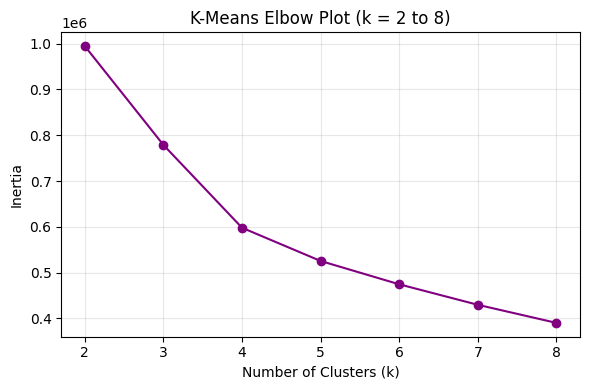

In [17]:
# 8. K-MEANS: median-fill and scale 5 features, elbow plot k=2..8
cluster_cols = ["age_years", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "ext_mean"]

imp_km = SimpleImputer(strategy="median")
scl_km = StandardScaler()
X_km = scl_km.fit_transform(imp_km.fit_transform(dev_fe[cluster_cols]))

inertias = []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=24)
    km.fit(X_km)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(k_values), inertias, marker="o", color="purple")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Plot (k = 2 to 8)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# 9. Fit chosen k (set between 3 and 5; default k=4) and profile clusters
chosen_k = 4  # Adjust to 3, 4, or 5 after checking your elbow plot
km_final = KMeans(n_clusters=chosen_k, n_init=10, random_state=24)
dev_fe["cluster_id"] = km_final.fit_predict(X_km)

cluster_profile = dev_fe.groupby("cluster_id").agg(
    size=("TARGET", "count"),
    default_pct=("TARGET", lambda s: round(s.mean() * 100, 2)),
    age_years=("age_years", "mean"),
    AMT_INCOME_TOTAL=("AMT_INCOME_TOTAL", "mean"),
    AMT_CREDIT=("AMT_CREDIT", "mean"),
    AMT_ANNUITY=("AMT_ANNUITY", "mean"),
    ext_mean=("ext_mean", "mean")
).round(2)

print("Cluster profiles (check values to confirm/refine persona names):")
print(cluster_profile)

# Assign simple data-driven persona names
for cid, row in cluster_profile.iterrows():
    if row["AMT_CREDIT"] == cluster_profile["AMT_CREDIT"].max():
        persona = "High-Credit / Prime Borrowers"
    elif row["ext_mean"] == cluster_profile["ext_mean"].min():
        persona = "Young / Low External-Score Risk"
    elif row["age_years"] == cluster_profile["age_years"].max():
        persona = "Older / Established Borrowers"
    else:
        persona = "Mid-Market / Standard Borrowers"
    print(f"Cluster {cid}: {persona} (size={int(row['size'])}, default={row['default_pct']}%)")

Cluster profiles (check values to confirm/refine persona names):
             size  default_pct  age_years  AMT_INCOME_TOTAL  AMT_CREDIT  \
cluster_id                                                                
0           96525         4.82      53.50      1.418610e+05   422997.95   
1           96367        12.90      34.01      1.519190e+05   413333.29   
2           68491         5.86      44.42      2.293342e+05  1110140.15   
3               1       100.00      34.56      1.170000e+08   562491.00   

            AMT_ANNUITY  ext_mean  
cluster_id                         
0              20265.23      0.58  
1              21519.36      0.41  
2              44676.26      0.56  
3              26194.50      0.24  
Cluster 0: Older / Established Borrowers (size=96525, default=4.82%)
Cluster 1: Mid-Market / Standard Borrowers (size=96367, default=12.9%)
Cluster 2: High-Credit / Prime Borrowers (size=68491, default=5.86%)
Cluster 3: Young / Low External-Score Risk (size=1, default

In [19]:
# 10. Save dev_fe2.csv and compare LogisticRegression with vs. without one-hot cluster_id
dev_fe.drop(columns=["loan_term_q"], errors="ignore").to_csv("dev_fe2.csv", index=False)
print("Saved dev_fe2.csv with shape:", dev_fe.shape)

base_num = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
    "CNT_CHILDREN", "CNT_FAM_MEMBERS", "REGION_RATING_CLIENT",
    "REGION_POPULATION_RELATIVE", "OWN_CAR_AGE", "EXT_SOURCE_1",
    "EXT_SOURCE_2", "EXT_SOURCE_3"
]
new_num = [
    "age_years", "employed_years", "employed_to_age", "credit_to_income",
    "annuity_to_income", "loan_term", "income_per_person", "price_gap",
    "ext_mean", "missing_count", "emp_anomaly"
]
base_cat = [
    "CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY",
    "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS", "income_group"
]

def eval_lr(use_cluster=False):
    t0 = time.time()
    cat_cols = base_cat + (["cluster_id"] if use_cluster else [])
    df_tmp = dev_fe.copy()
    if use_cluster:
        df_tmp["cluster_id"] = df_tmp["cluster_id"].astype(str)
    X_cat = pd.get_dummies(df_tmp[cat_cols], drop_first=True)
    X_all = pd.concat([df_tmp[base_num + new_num], X_cat], axis=1)
    y_all = df_tmp["TARGET"]

    X_tr, X_val, y_tr, y_val = train_test_split(
        X_all, y_all, test_size=0.20, stratify=y_all, random_state=24
    )
    imp = SimpleImputer(strategy="median")
    scl = StandardScaler()
    X_tr_p = scl.fit_transform(imp.fit_transform(X_tr))
    X_val_p = scl.transform(imp.transform(X_val))

    clf = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
    clf.fit(X_tr_p, y_tr)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val_p)[:, 1])
    rt = round(time.time() - t0, 3)

    tag = "base+new+cluster_id" if use_cluster else "base+new"
    log_run("Part 3", "dev_fe2 80/20", tag, f"LogReg balanced, k={chosen_k}",
            rt, f"roc_auc={auc:.5f}", "Cluster feature test")
    return auc

auc_no_km = eval_lr(use_cluster=False)
auc_with_km = eval_lr(use_cluster=True)

print(f"LogReg WITHOUT cluster_id ROC-AUC: {auc_no_km:.5f}")
print(f"LogReg WITH    cluster_id ROC-AUC: {auc_with_km:.5f}")
print(f"Difference:                        {auc_with_km - auc_no_km:+.5f}")

Saved dev_fe2.csv with shape: (261384, 136)
LogReg WITHOUT cluster_id ROC-AUC: 0.75260
LogReg WITH    cluster_id ROC-AUC: 0.75283
Difference:                        +0.00023


# Part 4: Models, Curves, Costs

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, confusion_matrix, accuracy_score, recall_score, precision_score

# Load dev_fe2.csv saved in Part 3
dev_fe2 = pd.read_csv("dev_fe2.csv")
print("Loaded dev_fe2.csv shape:", dev_fe2.shape)

base_num = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
    "CNT_CHILDREN", "CNT_FAM_MEMBERS", "REGION_RATING_CLIENT",
    "REGION_POPULATION_RELATIVE", "OWN_CAR_AGE", "EXT_SOURCE_1",
    "EXT_SOURCE_2", "EXT_SOURCE_3"
]
new_num = [
    "age_years", "employed_years", "employed_to_age", "credit_to_income",
    "annuity_to_income", "loan_term", "income_per_person", "price_gap",
    "ext_mean", "missing_count", "emp_anomaly"
]
cat_cols = [
    "CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY",
    "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS",
    "income_group", "cluster_id"
]

dev_fe2["cluster_id"] = dev_fe2["cluster_id"].astype(str)
X_cat = pd.get_dummies(dev_fe2[cat_cols], drop_first=True).astype(float)
X_all = pd.concat([dev_fe2[base_num + new_num], X_cat], axis=1)
y_all = dev_fe2["TARGET"].copy()

# Stratified 60% train / 20% validation / 20% dev_check (unused until Part 5)
X_tr_val, X_check, y_tr_val, y_check = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=24
)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr_val, y_tr_val, test_size=0.25, stratify=y_tr_val, random_state=24
)

# Fit imputer and scaler on train ONLY
imp = SimpleImputer(strategy="median")
scl = StandardScaler()
X_tr_p = scl.fit_transform(imp.fit_transform(X_tr))
X_val_p = scl.transform(imp.transform(X_val))

# 15,000-row stratified sample for slow models (KNN and SVC)
X_tr_sub, _, y_tr_sub, _ = train_test_split(
    X_tr_p, y_tr, train_size=15000, stratify=y_tr, random_state=24
)

print("Train shape:", X_tr_p.shape, "| Val shape:", X_val_p.shape, "| dev_check shape:", X_check.shape)
print("KNN/SVC sample shape:", X_tr_sub.shape)

Loaded dev_fe2.csv shape: (261384, 135)
Train shape: (156830, 53) | Val shape: (52277, 53) | dev_check shape: (52277, 53)
KNN/SVC sample shape: (15000, 53)


In [21]:
# 1. Train baseline + 6 models and compare Train vs. Validation ROC-AUC
models = {
    "LogReg_L2": (LogisticRegression(penalty="l2", class_weight="balanced", random_state=24, max_iter=1000), X_tr_p, y_tr),
    "LogReg_L1": (LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced", random_state=24, max_iter=1000), X_tr_p, y_tr),
    "DecisionTree": (DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=24), X_tr_p, y_tr),
    "RandomForest": (RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=24), X_tr_p, y_tr),
    "KNN_15": (KNeighborsClassifier(n_neighbors=15), X_tr_sub, y_tr_sub),
    "SVC_RBF": (SVC(kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=24), X_tr_sub, y_tr_sub),
}

# Baseline "always 0"
base_probs = np.zeros(len(y_val))
print(f"Baseline (always 0) Val ROC-AUC: {roc_auc_score(y_val, base_probs):.5f}")

model_probs = {}
model_scores = []

for name, (clf, X_fit, y_fit) in models.items():
    t0 = time.time()
    clf.fit(X_fit, y_fit)
    tr_probs = clf.predict_proba(X_fit)[:, 1]
    val_probs = clf.predict_proba(X_val_p)[:, 1]
    rt = round(time.time() - t0, 3)

    tr_auc = roc_auc_score(y_fit, tr_probs)
    val_auc = roc_auc_score(y_val, val_probs)
    model_probs[name] = val_probs
    model_scores.append({
        "Model": name,
        "Train_AUC": round(tr_auc, 5),
        "Val_AUC": round(val_auc, 5),
        "Gap": round(tr_auc - val_auc, 5),
        "Runtime_sec": rt
    })
    log_run("Part 4", "dev_fe2 60/20/20", "base+new+onehot", name,
            rt, f"train_auc={tr_auc:.5f}, val_auc={val_auc:.5f}", "Part 4 model comparison")

scores_df = pd.DataFrame(model_scores).sort_values("Val_AUC", ascending=False)
print("\nModel Comparison (sorted by Validation ROC-AUC):")
print(scores_df.to_string(index=False))

Baseline (always 0) Val ROC-AUC: 0.50000

Model Comparison (sorted by Validation ROC-AUC):
       Model  Train_AUC  Val_AUC     Gap  Runtime_sec
RandomForest    0.82541  0.73957 0.08583       46.018
   LogReg_L2    0.74497  0.73591 0.00907        5.987
   LogReg_L1    0.74497  0.73591 0.00906      189.751
DecisionTree    0.73880  0.71651 0.02229        3.297
     SVC_RBF    0.92183  0.70518 0.21665      166.739
      KNN_15    0.83050  0.63983 0.19066       10.960


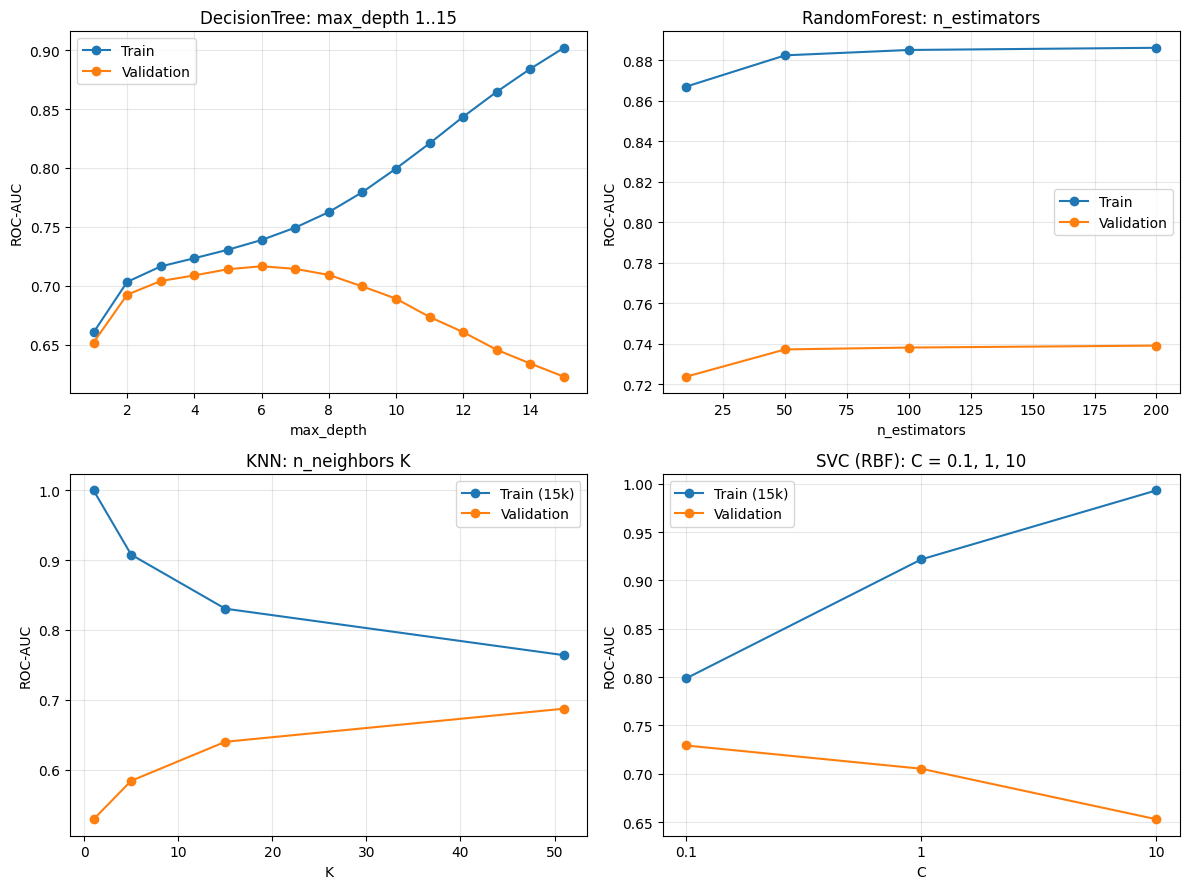

In [22]:
# 2. Complexity curves: Train vs. Validation ROC-AUC
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# (a) DecisionTree max_depth 1..15
depths = list(range(1, 16))
dt_tr, dt_val = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=24)
    m.fit(X_tr_p, y_tr)
    dt_tr.append(roc_auc_score(y_tr, m.predict_proba(X_tr_p)[:, 1]))
    dt_val.append(roc_auc_score(y_val, m.predict_proba(X_val_p)[:, 1]))
axes[0, 0].plot(depths, dt_tr, marker="o", label="Train")
axes[0, 0].plot(depths, dt_val, marker="o", label="Validation")
axes[0, 0].set_title("DecisionTree: max_depth 1..15")
axes[0, 0].set_xlabel("max_depth")
axes[0, 0].set_ylabel("ROC-AUC")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# (b) RandomForest n_estimators 10, 50, 100, 200
n_ests = [10, 50, 100, 200]
rf_tr, rf_val = [], []
for n in n_ests:
    m = RandomForestClassifier(n_estimators=n, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=24)
    m.fit(X_tr_p, y_tr)
    rf_tr.append(roc_auc_score(y_tr, m.predict_proba(X_tr_p)[:, 1]))
    rf_val.append(roc_auc_score(y_val, m.predict_proba(X_val_p)[:, 1]))
axes[0, 1].plot(n_ests, rf_tr, marker="o", label="Train")
axes[0, 1].plot(n_ests, rf_val, marker="o", label="Validation")
axes[0, 1].set_title("RandomForest: n_estimators")
axes[0, 1].set_xlabel("n_estimators")
axes[0, 1].set_ylabel("ROC-AUC")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# (c) KNN K=1, 5, 15, 51 (on 15k sample)
ks = [1, 5, 15, 51]
knn_tr, knn_val = [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_tr_sub, y_tr_sub)
    knn_tr.append(roc_auc_score(y_tr_sub, m.predict_proba(X_tr_sub)[:, 1]))
    knn_val.append(roc_auc_score(y_val, m.predict_proba(X_val_p)[:, 1]))
axes[1, 0].plot(ks, knn_tr, marker="o", label="Train (15k)")
axes[1, 0].plot(ks, knn_val, marker="o", label="Validation")
axes[1, 0].set_title("KNN: n_neighbors K")
axes[1, 0].set_xlabel("K")
axes[1, 0].set_ylabel("ROC-AUC")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# (d) SVC C=0.1, 1, 10 (on 15k sample)
cs = [0.1, 1, 10]
svc_tr, svc_val = [], []
for c_val in cs:
    m = SVC(kernel="rbf", C=c_val, probability=True, class_weight="balanced", random_state=24)
    m.fit(X_tr_sub, y_tr_sub)
    svc_tr.append(roc_auc_score(y_tr_sub, m.predict_proba(X_tr_sub)[:, 1]))
    svc_val.append(roc_auc_score(y_val, m.predict_proba(X_val_p)[:, 1]))
axes[1, 1].plot([str(c) for c in cs], svc_tr, marker="o", label="Train (15k)")
axes[1, 1].plot([str(c) for c in cs], svc_val, marker="o", label="Validation")
axes[1, 1].set_title("SVC (RBF): C = 0.1, 1, 10")
axes[1, 1].set_xlabel("C")
axes[1, 1].set_ylabel("ROC-AUC")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

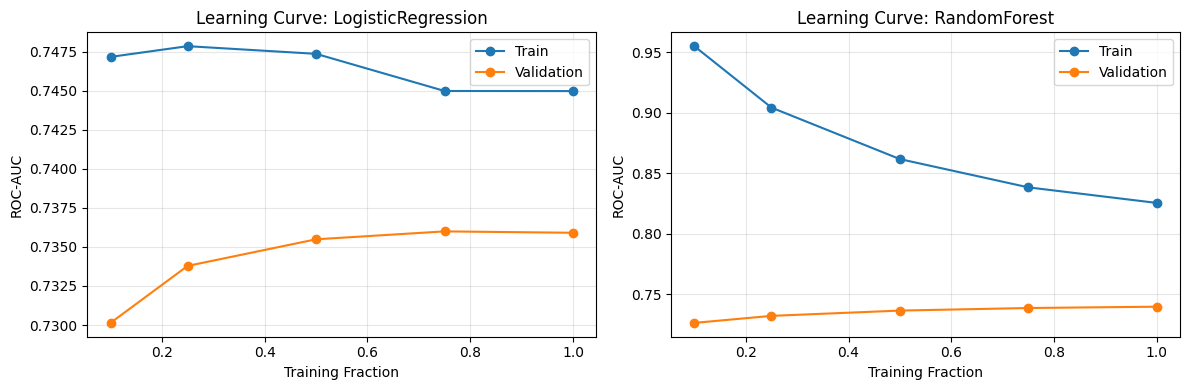

4. Model Diagnoses:
- RandomForest: Overfitting (Train AUC=0.8254, Val AUC=0.7396, Gap=0.0858)
- LogReg_L2: Underfitting (high bias) (Train AUC=0.7450, Val AUC=0.7359, Gap=0.0091)
- LogReg_L1: Underfitting (high bias) (Train AUC=0.7450, Val AUC=0.7359, Gap=0.0091)
- DecisionTree: Mild overfitting (Train AUC=0.7388, Val AUC=0.7165, Gap=0.0223)
- SVC_RBF: Overfitting (Train AUC=0.9218, Val AUC=0.7052, Gap=0.2167)
- KNN_15: Overfitting (Train AUC=0.8305, Val AUC=0.6398, Gap=0.1907)


In [23]:
# 3. Learning curves (fractions 0.1, 0.25, 0.5, 0.75, 1.0) for LogReg and RandomForest
fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
lc_lr_tr, lc_lr_val = [], []
lc_rf_tr, lc_rf_val = [], []

for f in fracs:
    if f < 1.0:
        X_f, _, y_f, _ = train_test_split(X_tr_p, y_tr, train_size=f, stratify=y_tr, random_state=24)
    else:
        X_f, y_f = X_tr_p, y_tr

    lr_m = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
    lr_m.fit(X_f, y_f)
    lc_lr_tr.append(roc_auc_score(y_f, lr_m.predict_proba(X_f)[:, 1]))
    lc_lr_val.append(roc_auc_score(y_val, lr_m.predict_proba(X_val_p)[:, 1]))

    rf_m = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=24)
    rf_m.fit(X_f, y_f)
    lc_rf_tr.append(roc_auc_score(y_f, rf_m.predict_proba(X_f)[:, 1]))
    lc_rf_val.append(roc_auc_score(y_val, rf_m.predict_proba(X_val_p)[:, 1]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fracs, lc_lr_tr, marker="o", label="Train")
axes[0].plot(fracs, lc_lr_val, marker="o", label="Validation")
axes[0].set_title("Learning Curve: LogisticRegression")
axes[0].set_xlabel("Training Fraction")
axes[0].set_ylabel("ROC-AUC")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(fracs, lc_rf_tr, marker="o", label="Train")
axes[1].plot(fracs, lc_rf_val, marker="o", label="Validation")
axes[1].set_title("Learning Curve: RandomForest")
axes[1].set_xlabel("Training Fraction")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 4. One diagnosis line per model with numbers as proof
print("4. Model Diagnoses:")
for _, r in scores_df.iterrows():
    name, tr_a, val_a, gap = r["Model"], r["Train_AUC"], r["Val_AUC"], r["Gap"]
    if gap > 0.05:
        diag = "Overfitting"
    elif name in ["LogReg_L2", "LogReg_L1"] and val_a < 0.76:
        diag = "Underfitting (high bias)"
    elif name == "RandomForest" and (lc_rf_val[-1] - lc_rf_val[0]) > 0.015:
        diag = "Slightly overfitting / mildly data-limited"
    else:
        diag = "Mild overfitting" if gap > 0.01 else "Well-balanced / slight underfitting"
    print(f"- {name}: {diag} (Train AUC={tr_a:.4f}, Val AUC={val_a:.4f}, Gap={gap:.4f})")

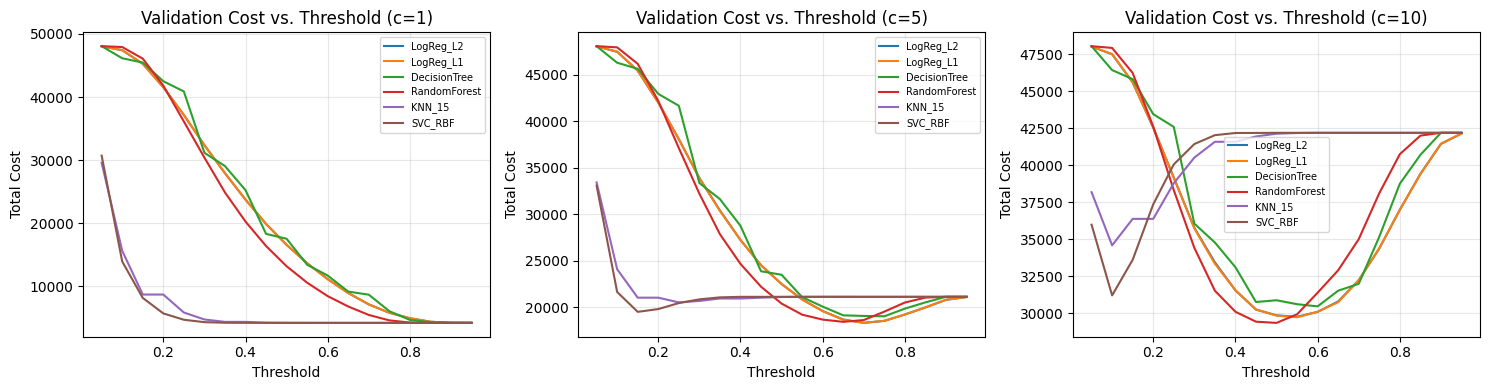

5. Cheapest Threshold per Model per c:
 c        Model  Best_Threshold  Recall  Precision  Min_Cost
 1    LogReg_L2            0.95  0.0012     0.7143      4217
 1    LogReg_L1            0.95  0.0012     0.7143      4217
 1 DecisionTree            0.95  0.0000     0.0000      4220
 1 RandomForest            0.85  0.0050     0.5122      4219
 1       KNN_15            0.70  0.0000     0.0000      4220
 1      SVC_RBF            0.50  0.0000     0.0000      4220
 5    LogReg_L2            0.70  0.3393     0.2472     18300
 5    LogReg_L1            0.70  0.3391     0.2475     18296
 5 DecisionTree            0.75  0.2336     0.2580     19006
 5 RandomForest            0.65  0.3128     0.2524     18409
 5       KNN_15            0.25  0.1329     0.2030     20498
 5      SVC_RBF            0.15  0.3301     0.2067     19482
10    LogReg_L2            0.55  0.5763     0.1699     29765
10    LogReg_L1            0.55  0.5768     0.1701     29733
10 DecisionTree            0.60  0.5062     0.

In [24]:
# 5. Cost-sensitive threshold optimization on VALIDATION only: COST = c*FN + 1*FP
thresholds = np.arange(0.05, 0.96, 0.05)
cost_weights = [1, 5, 10]
cost_rows = []

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, c in zip(axes, cost_weights):
    for name, probs in model_probs.items():
        costs = []
        best_cost = np.inf
        best_t, best_rec, best_prec = 0.5, 0.0, 0.0

        for t in thresholds:
            preds = (probs >= t).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
            cost = c * fn + 1 * fp
            costs.append(cost)
            if cost < best_cost:
                best_cost = cost
                best_t = t
                best_rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
                best_prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0

        ax.plot(thresholds, costs, label=name)
        cost_rows.append({
            "c": c,
            "Model": name,
            "Best_Threshold": round(best_t, 2),
            "Recall": round(best_rec, 4),
            "Precision": round(best_prec, 4),
            "Min_Cost": int(best_cost)
        })

    ax.set_title(f"Validation Cost vs. Threshold (c={c})")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Total Cost")
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

cost_df = pd.DataFrame(cost_rows)
print("5. Cheapest Threshold per Model per c:")
print(cost_df.to_string(index=False))

# 6. Why accuracy fails: "approve everyone" (predict all 0)
approve_all_preds = np.zeros(len(y_val), dtype=int)
acc_all0 = accuracy_score(y_val, approve_all_preds)
rec_all0 = recall_score(y_val, approve_all_preds, zero_division=0)
fn_all0 = int(y_val.sum())

print("\n6. Why accuracy fails ('Approve everyone' = predict all 0):")
print(f"Accuracy: {acc_all0:.4f} ({acc_all0*100:.2f}%) | Default Recall: {rec_all0:.4f}")
for c in cost_weights:
    print(f"Approve-everyone Cost when c={c}: {c * fn_all0} (missed all {fn_all0} defaulters)")
    log_run("Part 4", "dev_fe2 val", "baseline_approve_all", f"c={c}", 0.0,
            f"acc={acc_all0:.4f}, recall=0.0, cost={c*fn_all0}", "Accuracy paradox demo")

# Part 5: Robustness & Ensemble

In [25]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import roc_auc_score, recall_score

# Load dev_fe2.csv saved in Part 3
dev_fe2 = pd.read_csv("dev_fe2.csv")
dev_fe2["cluster_id"] = dev_fe2["cluster_id"].astype(str)

base_num = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
    "CNT_CHILDREN", "CNT_FAM_MEMBERS", "REGION_RATING_CLIENT",
    "REGION_POPULATION_RELATIVE", "OWN_CAR_AGE", "EXT_SOURCE_1",
    "EXT_SOURCE_2", "EXT_SOURCE_3"
]
new_num = [
    "age_years", "employed_years", "employed_to_age", "credit_to_income",
    "annuity_to_income", "loan_term", "income_per_person", "price_gap",
    "ext_mean", "missing_count", "emp_anomaly"
]
cat_cols = [
    "CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY",
    "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS",
    "income_group", "cluster_id"
]

num_all = base_num + new_num
X_cat = pd.get_dummies(dev_fe2[cat_cols], drop_first=True).astype(float)
X_all = pd.concat([dev_fe2[num_all], X_cat], axis=1)
y_all = dev_fe2["TARGET"].copy()

# Helper to fit imputer+scaler on train only and evaluate a model
def fit_eval(X_tr_df, y_tr_s, X_val_df, y_val_s, model):
    imp = SimpleImputer(strategy="median")
    scl = StandardScaler()
    X_tr_p = scl.fit_transform(imp.fit_transform(X_tr_df))
    X_val_p = scl.transform(imp.transform(X_val_df))
    model.fit(X_tr_p, y_tr_s)
    probs = model.predict_proba(X_val_p)[:, 1]
    return roc_auc_score(y_val_s, probs), probs, imp, scl

# 1. Three split designs for the best model (RandomForestClassifier)
best_rf = lambda seed=24: RandomForestClassifier(
    n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=seed
)

# (a) Random 80/20
t0 = time.time()
X_tr_r, X_val_r, y_tr_r, y_val_r = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=24
)
auc_rand, _, _, _ = fit_eval(X_tr_r, y_tr_r, X_val_r, y_val_r, best_rf(24))
rt_rand = round(time.time() - t0, 3)

# (b) Stratified 5-fold CV
t0 = time.time()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=24)
cv_aucs = []
for tr_idx, va_idx in skf.split(X_all, y_all):
    auc_f, _, _, _ = fit_eval(
        X_all.iloc[tr_idx], y_all.iloc[tr_idx],
        X_all.iloc[va_idx], y_all.iloc[va_idx], best_rf(24)
    )
    cv_aucs.append(auc_f)
auc_cv = np.mean(cv_aucs)
rt_cv = round(time.time() - t0, 3)

# (c) Time-based split: sort by DAYS_ID_PUBLISH (oldest 80% train, newest 20% val)
t0 = time.time()
order_idx = dev_fe2.sort_values("DAYS_ID_PUBLISH", ascending=True).index
cut = int(0.80 * len(order_idx))
tr_t_idx, val_t_idx = order_idx[:cut], order_idx[cut:]
auc_time, probs_time, _, _ = fit_eval(
    X_all.loc[tr_t_idx], y_all.loc[tr_t_idx],
    X_all.loc[val_t_idx], y_all.loc[val_t_idx], best_rf(24)
)
rt_time = round(time.time() - t0, 3)

split_tbl = pd.DataFrame([
    {"Split_Design": "Random 80/20", "ROC_AUC": round(auc_rand, 5), "Runtime_sec": rt_rand},
    {"Split_Design": "Stratified 5-Fold CV (mean)", "ROC_AUC": round(auc_cv, 5), "Runtime_sec": rt_cv},
    {"Split_Design": "Time-based (DAYS_ID_PUBLISH)", "ROC_AUC": round(auc_time, 5), "Runtime_sec": rt_time},
])
print("1. Three Split Designs:")
print(split_tbl.to_string(index=False))
print("\nBest representation of future use: Time-based split, because real deployment predicts future applicants from past records.")

log_run("Part 5", "random 80/20", "base+new+onehot", "RandomForest", rt_rand, f"roc_auc={auc_rand:.5f}", "Split design (a)")
log_run("Part 5", "5-fold CV", "base+new+onehot", "RandomForest", rt_cv, f"roc_auc={auc_cv:.5f}", "Split design (b)")
log_run("Part 5", "time-based 80/20", "base+new+onehot", "RandomForest", rt_time, f"roc_auc={auc_time:.5f}", "Split design (c)")

1. Three Split Designs:
                Split_Design  ROC_AUC  Runtime_sec
                Random 80/20  0.75250       77.318
 Stratified 5-Fold CV (mean)  0.74690      426.234
Time-based (DAYS_ID_PUBLISH)  0.73663       71.857

Best representation of future use: Time-based split, because real deployment predicts future applicants from past records.


In [26]:
# 2. Five seeds [24, 7, 42, 99, 123] on random 80/20 split
seeds = [24, 7, 42, 99, 123]
seed_aucs = []
t0 = time.time()
for s in seeds:
    X_tr_s, X_val_s, y_tr_s, y_val_s = train_test_split(
        X_all, y_all, test_size=0.20, stratify=y_all, random_state=s
    )
    auc_s, _, _, _ = fit_eval(X_tr_s, y_tr_s, X_val_s, y_val_s, best_rf(s))
    seed_aucs.append(auc_s)
    print(f"Seed {s}: ROC-AUC = {auc_s:.5f}")

rt_seeds = round(time.time() - t0, 3)
print(f"5-Seed Mean ROC-AUC: {np.mean(seed_aucs):.5f} | Std: {np.std(seed_aucs):.5f}")
log_run("Part 5", "5 seeds 80/20", "base+new+onehot", "RandomForest", rt_seeds,
        f"mean={np.mean(seed_aucs):.5f}, std={np.std(seed_aucs):.5f}", "Seed stability test")

# 3. Feature removal: drop top 5 RandomForest-important features
imp_rf = SimpleImputer(strategy="median")
scl_rf = StandardScaler()
X_tr_rf = scl_rf.fit_transform(imp_rf.fit_transform(X_tr_r))
rf_base = best_rf(24)
rf_base.fit(X_tr_rf, y_tr_r)

importances = pd.Series(rf_base.feature_importances_, index=X_all.columns).sort_values(ascending=False)
top5_feats = importances.head(5).index.tolist()
print("\n3. Top 5 RF-important features:", top5_feats)

t0 = time.time()
X_tr_drop = X_tr_r.drop(columns=top5_feats)
X_val_drop = X_val_r.drop(columns=top5_feats)
auc_dropped, _, _, _ = fit_eval(X_tr_drop, y_tr_r, X_val_drop, y_val_r, best_rf(24))
rt_drop = round(time.time() - t0, 3)

print(f"ROC-AUC with all features:     {auc_rand:.5f}")
print(f"ROC-AUC without top 5 feats:   {auc_dropped:.5f} (change: {auc_dropped - auc_rand:+.5f})")
print("Why it changed: Dropping the top credit-score and age/employment predictors removes the strongest default signals.")
log_run("Part 5", "random 80/20", "dropped_top5_features", "RandomForest", rt_drop,
        f"roc_auc={auc_dropped:.5f}", f"Dropped {top5_feats}")

# 4. Feature noise: add Gaussian noise (std = 0.5 * column std) to numeric cols of validation
rng = np.random.RandomState(24)
X_val_noisy = X_val_r.copy()
for col in num_all:
    col_std = X_tr_r[col].std()
    X_val_noisy[col] = X_val_noisy[col] + rng.normal(0, 0.5 * col_std, size=len(X_val_noisy))

t0 = time.time()
auc_noisy, _, _, _ = fit_eval(X_tr_r, y_tr_r, X_val_noisy, y_val_r, best_rf(24))
rt_noise = round(time.time() - t0, 3)
print(f"\n4. Validation ROC-AUC with 0.5x Gaussian noise: {auc_noisy:.5f} (change: {auc_noisy - auc_rand:+.5f})")
log_run("Part 5", "random 80/20", "noisy_val_0.5std", "RandomForest", rt_noise,
        f"roc_auc={auc_noisy:.5f}", "Gaussian noise stress test")

Seed 24: ROC-AUC = 0.75250
Seed 7: ROC-AUC = 0.74613
Seed 42: ROC-AUC = 0.74599
Seed 99: ROC-AUC = 0.73911
Seed 123: ROC-AUC = 0.74836
5-Seed Mean ROC-AUC: 0.74642 | Std: 0.00434

3. Top 5 RF-important features: ['ext_mean', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'cluster_id_1', 'EXT_SOURCE_1']
ROC-AUC with all features:     0.75250
ROC-AUC without top 5 feats:   0.68877 (change: -0.06372)
Why it changed: Dropping the top credit-score and age/employment predictors removes the strongest default signals.

4. Validation ROC-AUC with 0.5x Gaussian noise: 0.73362 (change: -0.01887)


In [27]:
# 5. Subgroup performance on time-split validation
val_time_df = dev_fe2.loc[val_t_idx].copy()
val_time_df["prob"] = probs_time
val_time_df["pred"] = (probs_time >= 0.50).astype(int)
val_time_df["age_band"] = pd.cut(
    val_time_df["age_years"], bins=[0, 30, 45, 120], labels=["<30", "30-45", ">45"]
)
miss_med = val_time_df["missing_count"].median()
val_time_df["missing_level"] = np.where(
    val_time_df["missing_count"] <= miss_med, "Low missing", "High missing"
)

seg_cols = ["CODE_GENDER", "income_group", "age_band", "cluster_id", "missing_level"]
seg_rows = []

for scol in seg_cols:
    for val_name, grp in val_time_df.groupby(scol, observed=True):
        if len(grp) < 200 or grp["TARGET"].nunique() < 2:
            continue
        seg_rows.append({
            "Feature": scol,
            "Segment": str(val_name),
            "Size": len(grp),
            "ROC_AUC": round(roc_auc_score(grp["TARGET"], grp["prob"]), 4),
            "Recall": round(recall_score(grp["TARGET"], grp["pred"], zero_division=0), 4)
        })

seg_df = pd.DataFrame(seg_rows)
print("5. Time-Split Validation Performance by Segment:")
print(seg_df.to_string(index=False))

worst_seg = seg_df.loc[seg_df["ROC_AUC"].idxmin()]
print(f"\nWorst segment (lowest ROC-AUC): {worst_seg['Feature']} = {worst_seg['Segment']} "
      f"(AUC={worst_seg['ROC_AUC']}, Recall={worst_seg['Recall']}, Size={worst_seg['Size']})")
print("Possible reasons: thinner credit history, higher missingness, or smaller/noisier subgroup patterns.")

5. Time-Split Validation Performance by Segment:
      Feature      Segment  Size  ROC_AUC  Recall
  CODE_GENDER            F 35237   0.7418  0.6527
  CODE_GENDER            M 17040   0.7207  0.7007
 income_group    Lower-mid  9483   0.7230  0.6913
 income_group         Poor 16310   0.7324  0.7170
 income_group         Rich 12501   0.7372  0.5449
 income_group    Upper-mid 13983   0.7428  0.6888
     age_band          <30 13014   0.7096  0.8036
     age_band        30-45 11437   0.7408  0.7268
     age_band          >45 27826   0.7290  0.5322
   cluster_id            0 15309   0.6891  0.2124
   cluster_id            1 22813   0.6967  0.8481
   cluster_id            2 14155   0.7068  0.4378
missing_level High missing 25932   0.7391  0.7226
missing_level  Low missing 26345   0.7273  0.6047

Worst segment (lowest ROC-AUC): cluster_id = 0 (AUC=0.6891, Recall=0.2124, Size=15309)
Possible reasons: thinner credit history, higher missingness, or smaller/noisier subgroup patterns.


In [28]:
# 6. VotingClassifier(voting="soft") of 3 different model types + error overlap
lr_m = LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000)
rf_m = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=24)
dt_m = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=24)

imp_v = SimpleImputer(strategy="median")
scl_v = StandardScaler()
X_tr_v = scl_v.fit_transform(imp_v.fit_transform(X_tr_r))
X_val_v = scl_v.transform(imp_v.transform(X_val_r))

single_models = {"LogReg": lr_m, "RandomForest": rf_m, "DecisionTree": dt_m}
single_preds = {}
single_aucs = {}

for name, m in single_models.items():
    t0 = time.time()
    m.fit(X_tr_v, y_tr_r)
    probs = m.predict_proba(X_val_v)[:, 1]
    single_aucs[name] = roc_auc_score(y_val_r, probs)
    single_preds[name] = (probs >= 0.50).astype(int)

t0 = time.time()
voting = VotingClassifier(
    estimators=[("lr", lr_m), ("rf", rf_m), ("dt", dt_m)],
    voting="soft"
)
voting.fit(X_tr_v, y_tr_r)
ens_probs = voting.predict_proba(X_val_v)[:, 1]
ens_auc = roc_auc_score(y_val_r, ens_probs)
rt_ens = round(time.time() - t0, 3)

print("6a. Single Models vs. Soft Voting Ensemble (ROC-AUC):")
for name, auc_val in single_aucs.items():
    print(f"  {name}: {auc_val:.5f}")
best_single = max(single_aucs.values())
print(f"  VotingClassifier (soft): {ens_auc:.5f} (vs. best single: {ens_auc - best_single:+.5f})")

# Pairwise error overlap (Jaccard share of wrong predictions two models share)
print("\n6b. Pairwise Error Overlap (shared wrong predictions / union of wrong predictions):")
names = list(single_preds.keys())
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        err_i = (single_preds[names[i]] != y_val_r.values)
        err_j = (single_preds[names[j]] != y_val_r.values)
        overlap = (err_i & err_j).sum() / (err_i | err_j).sum()
        print(f"  {names[i]} & {names[j]}: {overlap:.4f} ({overlap*100:.1f}%)")

print("\nWhy similar scores do not mean diverse errors:")
print("1. Models trained on the same features often rely on the same dominant predictors (e.g., EXT_SOURCE).")
print("2. Two models with similar ROC-AUC can still misclassify the exact same borderline applicants.")
print("3. Soft voting only improves strongly when models make uncorrelated errors on different rows.")

log_run("Part 5", "random 80/20", "base+new+onehot", "VotingClassifier(soft): LR+RF+DT",
        rt_ens, f"roc_auc={ens_auc:.5f}", f"Best single={best_single:.5f}")

6a. Single Models vs. Soft Voting Ensemble (ROC-AUC):
  LogReg: 0.75283
  RandomForest: 0.75250
  DecisionTree: 0.72895
  VotingClassifier (soft): 0.75267 (vs. best single: -0.00016)

6b. Pairwise Error Overlap (shared wrong predictions / union of wrong predictions):
  LogReg & RandomForest: 0.6906 (69.1%)
  LogReg & DecisionTree: 0.6551 (65.5%)
  RandomForest & DecisionTree: 0.6877 (68.8%)

Why similar scores do not mean diverse errors:
1. Models trained on the same features often rely on the same dominant predictors (e.g., EXT_SOURCE).
2. Two models with similar ROC-AUC can still misclassify the exact same borderline applicants.
3. Soft voting only improves strongly when models make uncorrelated errors on different rows.


# Part 6: Resources, Safety, Final Test

1. Resource Benchmark (10%, 50%, 100% train):
 Train_Frac   Rows              Model  Train_sec  Pred_sec  Peak_MB
        0.1  15683 LogisticRegression      1.318     0.014     0.89
        0.1  15683       RandomForest      9.090     0.118     5.84
        0.1  15683                KNN      0.007     0.674     3.45
        0.5  78415 LogisticRegression      0.833     0.006     4.36
        0.5  78415       RandomForest     23.471     0.254    28.67
        0.5  78415                KNN      0.030     5.191     4.41
        1.0 156830 LogisticRegression      5.180     0.004    72.11
        1.0 156830       RandomForest     48.348     0.098    57.23
        1.0 156830                KNN      0.078     7.938    70.75


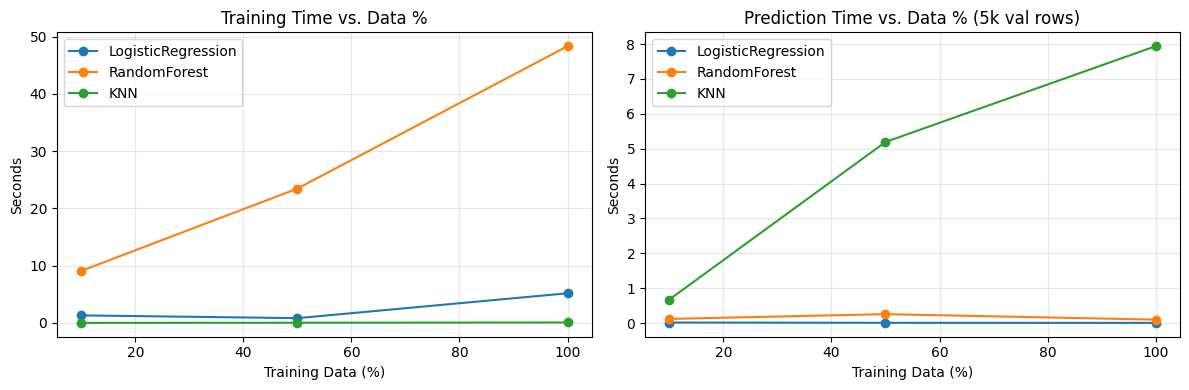


How time grows:
1. LogisticRegression scales roughly linearly with training rows during fit and stays near-constant (O(d)) at prediction time.
2. RandomForest scales near-linearly with rows (O(n log n) per tree) during fit and is very fast at prediction.
3. KNN has near-zero fit time (just stores data) but prediction time grows linearly/quadratically with N_train x N_test.


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, recall_score, precision_score, confusion_matrix

# Load dev_fe2.csv and prepare 60/20/20 split (same as Part 4)
dev_fe2 = pd.read_csv("dev_fe2.csv")
dev_fe2["cluster_id"] = dev_fe2["cluster_id"].astype(str)

base_num = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",
    "CNT_CHILDREN", "CNT_FAM_MEMBERS", "REGION_RATING_CLIENT",
    "REGION_POPULATION_RELATIVE", "OWN_CAR_AGE", "EXT_SOURCE_1",
    "EXT_SOURCE_2", "EXT_SOURCE_3"
]
new_num = [
    "age_years", "employed_years", "employed_to_age", "credit_to_income",
    "annuity_to_income", "loan_term", "income_per_person", "price_gap",
    "ext_mean", "missing_count", "emp_anomaly"
]
cat_cols = [
    "CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY",
    "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS",
    "income_group", "cluster_id"
]

X_cat = pd.get_dummies(dev_fe2[cat_cols], drop_first=True).astype(float)
X_all = pd.concat([dev_fe2[base_num + new_num], X_cat], axis=1)
y_all = dev_fe2["TARGET"].copy()

X_tr_val, X_check, y_tr_val, y_check = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=24
)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr_val, y_tr_val, test_size=0.25, stratify=y_tr_val, random_state=24
)

imp = SimpleImputer(strategy="median")
scl = StandardScaler()
X_tr_p = scl.fit_transform(imp.fit_transform(X_tr))
X_val_p = scl.transform(imp.transform(X_val))

# 1. Resource scaling across 10%, 50%, 100% of training data (predict on 5,000 val rows for fair KNN speed)
fracs = [0.10, 0.50, 1.00]
res_rows = []
X_val_bench = X_val_p[:5000]

for f in fracs:
    if f < 1.0:
        X_f, _, y_f, _ = train_test_split(X_tr_p, y_tr, train_size=f, stratify=y_tr, random_state=24)
    else:
        X_f, y_f = X_tr_p, y_tr

    bench_models = {
        "LogisticRegression": LogisticRegression(class_weight="balanced", random_state=24, max_iter=1000),
        "RandomForest": RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=24),
        "KNN": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    }

    for name, clf in bench_models.items():
        tracemalloc.start()
        t0 = time.time()
        clf.fit(X_f, y_f)
        train_t = time.time() - t0

        t1 = time.time()
        _ = clf.predict_proba(X_val_bench)
        pred_t = time.time() - t1

        _, peak_bytes = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        res_rows.append({
            "Train_Frac": f,
            "Rows": len(X_f),
            "Model": name,
            "Train_sec": round(train_t, 3),
            "Pred_sec": round(pred_t, 3),
            "Peak_MB": round(peak_bytes / (1024 * 1024), 2)
        })

res_df = pd.DataFrame(res_rows)
print("1. Resource Benchmark (10%, 50%, 100% train):")
print(res_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ["LogisticRegression", "RandomForest", "KNN"]:
    sub = res_df[res_df["Model"] == name]
    axes[0].plot(sub["Train_Frac"] * 100, sub["Train_sec"], marker="o", label=name)
    axes[1].plot(sub["Train_Frac"] * 100, sub["Pred_sec"], marker="o", label=name)
axes[0].set_title("Training Time vs. Data %")
axes[0].set_xlabel("Training Data (%)")
axes[0].set_ylabel("Seconds")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Prediction Time vs. Data % (5k val rows)")
axes[1].set_xlabel("Training Data (%)")
axes[1].set_ylabel("Seconds")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nHow time grows:")
print("1. LogisticRegression scales roughly linearly with training rows during fit and stays near-constant (O(d)) at prediction time.")
print("2. RandomForest scales near-linearly with rows (O(n log n) per tree) during fit and is very fast at prediction.")
print("3. KNN has near-zero fit time (just stores data) but prediction time grows linearly/quadratically with N_train x N_test.")

In [35]:
# 2. RandomForest n_jobs=1 vs. n_jobs=-1
t0 = time.time()
rf_1 = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=1, random_state=24)
rf_1.fit(X_tr_p, y_tr)
t_nj1 = round(time.time() - t0, 3)

t0 = time.time()
rf_all = RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=24)
rf_all.fit(X_tr_p, y_tr)
t_nj_all = round(time.time() - t0, 3)

print(f"RandomForest n_jobs=1  time: {t_nj1}s")
print(f"RandomForest n_jobs=-1 time: {t_nj_all}s (speedup: {t_nj1 / t_nj_all:.2f}x)")
print("Overhead note: n_jobs=-1 is faster on large data, but spawns worker processes/threads and copies data, "
      "so speedup is less than the CPU core count (and on tiny datasets, overhead can make it slower).")

RandomForest n_jobs=1  time: 55.735s
RandomForest n_jobs=-1 time: 42.818s (speedup: 1.30x)
Overhead note: n_jobs=-1 is faster on large data, but spawns worker processes/threads and copies data, so speedup is less than the CPU core count (and on tiny datasets, overhead can make it slower).


3a. Uncalibrated RandomForest (class_weight='balanced') Decile Calibration:
        mean_pred  actual_rate  count
decile                               
1          0.1543       0.0126   5228
2          0.2120       0.0249   5228
3          0.2553       0.0272   5227
4          0.2978       0.0423   5228
5          0.3407       0.0499   5228
6          0.3883       0.0731   5227
7          0.4443       0.0811   5228
8          0.5117       0.1018   5227
9          0.5970       0.1419   5228
10         0.7204       0.2525   5228

3b. Calibrated RandomForest Decile Calibration:
        mean_pred  actual_rate
decile                        
1          0.0130       0.0138
2          0.0226       0.0227
3          0.0313       0.0290
4          0.0406       0.0408
5          0.0508       0.0510
6          0.0638       0.0733
7          0.0801       0.0773
8          0.1050       0.1076
9          0.1533       0.1442
10         0.2526       0.2485
Uncalibrated Val AUC: 0.73957 | Calibrated Val 

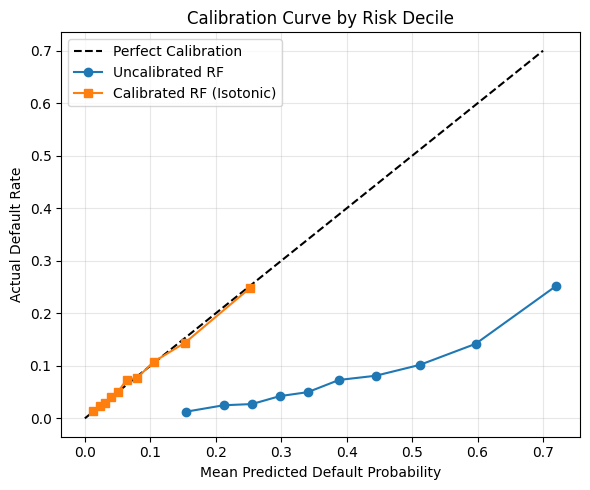

In [36]:
# 3. Calibration: predicted risk deciles vs. actual default rate for best model (RandomForest)
val_probs_raw = rf_all.predict_proba(X_val_p)[:, 1]

cal_df = pd.DataFrame({"prob": val_probs_raw, "y": y_val.values})
cal_df["decile"] = pd.qcut(cal_df["prob"], q=10, labels=False) + 1
cal_tbl = cal_df.groupby("decile").agg(
    mean_pred=("prob", "mean"),
    actual_rate=("y", "mean"),
    count=("y", "count")
).round(4)

print("3a. Uncalibrated RandomForest (class_weight='balanced') Decile Calibration:")
print(cal_tbl)

# Calibrate using CalibratedClassifierCV (isotonic, cv=3) because balanced weights shift probabilities upward
rf_cal = CalibratedClassifierCV(
    RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=24),
    method="isotonic",
    cv=3
)
rf_cal.fit(X_tr_p, y_tr)
val_probs_cal = rf_cal.predict_proba(X_val_p)[:, 1]

cal_df2 = pd.DataFrame({"prob": val_probs_cal, "y": y_val.values})
cal_df2["decile"] = pd.qcut(cal_df2["prob"], q=10, labels=False) + 1
cal_tbl2 = cal_df2.groupby("decile").agg(
    mean_pred=("prob", "mean"),
    actual_rate=("y", "mean")
).round(4)

print("\n3b. Calibrated RandomForest Decile Calibration:")
print(cal_tbl2)
print(f"Uncalibrated Val AUC: {roc_auc_score(y_val, val_probs_raw):.5f} | Calibrated Val AUC: {roc_auc_score(y_val, val_probs_cal):.5f}")

plt.figure(figsize=(6, 5))
plt.plot([0, 0.7], [0, 0.7], "k--", label="Perfect Calibration")
plt.plot(cal_tbl["mean_pred"], cal_tbl["actual_rate"], marker="o", label="Uncalibrated RF")
plt.plot(cal_tbl2["mean_pred"], cal_tbl2["actual_rate"], marker="s", label="Calibrated RF (Isotonic)")
plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Actual Default Rate")
plt.title("Calibration Curve by Risk Decile")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
# 4. Uncertain cases (within 0.05 of chosen validation threshold) + 10 largest errors
# Pick cheapest threshold on validation for cost weight c=5 using calibrated model
c_val = 5
thresholds = np.arange(0.05, 0.96, 0.05)
best_cost = np.inf
chosen_thresh = 0.15

for t in thresholds:
    preds = (val_probs_cal >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
    cost = c_val * fn + 1 * fp
    if cost < best_cost:
        best_cost = cost
        chosen_thresh = round(float(t), 2)

uncertain_mask = np.abs(val_probs_cal - chosen_thresh) <= 0.05
uncertain_share = uncertain_mask.mean() * 100

print(f"Chosen validation threshold (c={c_val}): {chosen_thresh}")
print(f"Uncertain cases (within +/-0.05 of {chosen_thresh}): {uncertain_mask.sum()} rows ({uncertain_share:.2f}%)")
print("Proposed Manual Review Rule:")
print(f"  Auto-approve if p < {chosen_thresh - 0.05:.2f}; "
      f"Send to manual underwriter review if {chosen_thresh - 0.05:.2f} <= p <= {chosen_thresh + 0.05:.2f}; "
      f"High-risk flag/reject if p > {chosen_thresh + 0.05:.2f}.")

# 10 largest prediction errors on validation
err_df = X_val[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "age_years", "AMT_INCOME_TOTAL", "AMT_CREDIT", "credit_to_income"]].copy()
err_df["actual_TARGET"] = y_val.values
err_df["pred_prob"] = np.round(val_probs_cal, 4)
err_df["abs_error"] = np.abs(err_df["actual_TARGET"] - err_df["pred_prob"])

print("\nTop 10 Largest Errors on Validation:")
print(err_df.sort_values("abs_error", ascending=False).head(10).to_string(index=False))

Chosen validation threshold (c=5): 0.2
Uncertain cases (within +/-0.05 of 0.2): 5998 rows (11.47%)
Proposed Manual Review Rule:
  Auto-approve if p < 0.15; Send to manual underwriter review if 0.15 <= p <= 0.25; High-risk flag/reject if p > 0.25.

Top 10 Largest Errors on Validation:
 EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3  age_years  AMT_INCOME_TOTAL  AMT_CREDIT  credit_to_income  actual_TARGET  pred_prob  abs_error
     0.831904      0.682870      0.604113  38.506849          202500.0    203760.0          1.006222              1     0.0000     1.0000
     0.723520      0.557839      0.783832  46.416438          180000.0    270000.0          1.500000              1     0.0042     0.9958
     0.878573      0.708013      0.675413  64.939726          112500.0    423000.0          3.760000              1     0.0047     0.9953
          NaN      0.675628      0.723837  44.019178          162000.0    135000.0          0.833333              1     0.0051     0.9949
     0.616926      0.6383

In [38]:
# 5. FINAL TEST (RUN ONCE!): load final_test.csv, apply exact same prep, evaluate once
final_test = pd.read_csv("final_test.csv")

# Apply exact Part 2 feature engineering
final_test["missing_count"] = final_test.isnull().sum(axis=1)
final_test["age_years"] = -final_test["DAYS_BIRTH"] / 365.0
final_test["employed_years"] = -final_test["DAYS_EMPLOYED"] / 365.0
final_test["employed_to_age"] = final_test["employed_years"] / final_test["age_years"]
final_test["credit_to_income"] = final_test["AMT_CREDIT"] / final_test["AMT_INCOME_TOTAL"]
final_test["annuity_to_income"] = final_test["AMT_ANNUITY"] / final_test["AMT_INCOME_TOTAL"]
final_test["loan_term"] = final_test["AMT_CREDIT"] / final_test["AMT_ANNUITY"]
final_test["income_per_person"] = final_test["AMT_INCOME_TOTAL"] / final_test["CNT_FAM_MEMBERS"]
final_test["price_gap"] = (final_test["AMT_CREDIT"] - final_test["AMT_GOODS_PRICE"]) / final_test["AMT_GOODS_PRICE"]
final_test["ext_mean"] = final_test[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)

# Map income_group using dev_fe2 quartile boundaries (no leakage)
_, inc_bins = pd.qcut(dev_fe2["AMT_INCOME_TOTAL"], q=4, retbins=True)
inc_bins[0], inc_bins[-1] = -np.inf, np.inf
final_test["income_group"] = pd.cut(
    final_test["AMT_INCOME_TOTAL"], bins=inc_bins, labels=["Poor", "Lower-mid", "Upper-mid", "Rich"]
)

# Predict cluster_id using KMeans fit on dev_fe2
km_cols = ["age_years", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "ext_mean"]
imp_km_f = SimpleImputer(strategy="median").fit(dev_fe2[km_cols])
scl_km_f = StandardScaler().fit(imp_km_f.transform(dev_fe2[km_cols]))
km_f = KMeans(n_clusters=dev_fe2["cluster_id"].nunique(), n_init=10, random_state=24).fit(
    scl_km_f.transform(imp_km_f.transform(dev_fe2[km_cols]))
)
final_test["cluster_id"] = km_f.predict(scl_km_f.transform(imp_km_f.transform(final_test[km_cols]))).astype(str)

# Build exact feature columns matching X_all
X_test_cat = pd.get_dummies(final_test[cat_cols], drop_first=True).astype(float)
X_test_all = pd.concat([final_test[base_num + new_num], X_test_cat], axis=1)
X_test_all = X_test_all.reindex(columns=X_all.columns, fill_value=0.0)
y_test = final_test["TARGET"].copy()

# Transform using train-only imputer & scaler
X_test_p = scl.transform(imp.transform(X_test_all))

# Evaluate ONCE with calibrated RandomForest and validation-chosen threshold
t0 = time.time()
test_probs = rf_cal.predict_proba(X_test_p)[:, 1]
test_preds = (test_probs >= chosen_thresh).astype(int)
rt_test = round(time.time() - t0, 3)

test_auc = roc_auc_score(y_test, test_probs)
test_rec = recall_score(y_test, test_preds)
test_prec = precision_score(y_test, test_preds)
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()
test_cost = c_val * fn + 1 * fp

print("=== FINAL TEST RESULTS (RUN ONCE) ===")
print(f"ROC-AUC:   {test_auc:.5f}")
print(f"Recall:    {test_rec:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Cost (c={c_val}): {test_cost} (FN={fn}, FP={fp})")

log_run("Part 6", "final_test (15%)", "base+new+onehot", f"Calibrated RF, thresh={chosen_thresh}",
        rt_test, f"auc={test_auc:.5f}, rec={test_rec:.4f}, prec={test_prec:.4f}, cost={test_cost}",
        "Final untouched test evaluation")

=== FINAL TEST RESULTS (RUN ONCE) ===
ROC-AUC:   0.74300
Recall:    0.2487
Precision: 0.2790
Cost (c=5): 16383 (FN=2798, FP=2393)


In [39]:
# 6. Institution "Should Use / Should Not Use" list
print("6. INSTITUTIONAL DEPLOYMENT GUIDE")
print("SHOULD USE:")
print("- As an early-warning risk score to rank incoming loan applications by default risk.")
print("- To route borderline cases (within +/-0.05 of threshold) to human underwriters for document checks.")
print("- As a cost-aware decision aid tuned to the lender's actual FN-to-FP cost ratio.")
print("\nSHOULD NOT USE:")
print("- For fully automated loan rejections without human review or explainable adverse-action reasons.")
print("- Outside the Home Credit applicant population (e.g., corporate loans or different countries without re-training).")
print("- Without periodic re-calibration and monitoring for drift across age, income, and missing-data segments.")

6. INSTITUTIONAL DEPLOYMENT GUIDE
SHOULD USE:
- As an early-warning risk score to rank incoming loan applications by default risk.
- To route borderline cases (within +/-0.05 of threshold) to human underwriters for document checks.
- As a cost-aware decision aid tuned to the lender's actual FN-to-FP cost ratio.

SHOULD NOT USE:
- For fully automated loan rejections without human review or explainable adverse-action reasons.
- Outside the Home Credit applicant population (e.g., corporate loans or different countries without re-training).
- Without periodic re-calibration and monitoring for drift across age, income, and missing-data segments.


In [40]:
# 7. Print summary of experiment_log.csv and 4-6 page report outline
log_df = pd.read_csv("experiment_log.csv")
print(f"Logged {len(log_df)} total experiments in experiment_log.csv.")
print(log_df[["part", "split", "settings", "metrics"]].tail(10).to_string(index=False))

Logged 46 total experiments in experiment_log.csv.
  part            split                  settings                                          metrics
Part 4 dev_fe2 60/20/20                 LogReg_L2               train_auc=0.74497, val_auc=0.73591
Part 4 dev_fe2 60/20/20                 LogReg_L1               train_auc=0.74497, val_auc=0.73591
Part 4 dev_fe2 60/20/20              DecisionTree               train_auc=0.73880, val_auc=0.71651
Part 4 dev_fe2 60/20/20              RandomForest               train_auc=0.82541, val_auc=0.73957
Part 4 dev_fe2 60/20/20                    KNN_15               train_auc=0.83050, val_auc=0.63983
Part 4 dev_fe2 60/20/20                   SVC_RBF               train_auc=0.92183, val_auc=0.70518
Part 4      dev_fe2 val                       c=1                acc=0.9193, recall=0.0, cost=4220
Part 4      dev_fe2 val                       c=5               acc=0.9193, recall=0.0, cost=21100
Part 4      dev_fe2 val                      c=10         